<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Agreement of the transcript classification across default, Proseg and Segger segmentations.
> - **Manuscript panels:** ED Fig. 1C
> - **Inputs:** Per-transcript classifications as in notebook 11
> - **Outputs:** River (alluvial) plot and pairwise confusion matrices
> - **Environment / kernel:** `troutpy_drvi (executed with `12_run_notebook.sbatch`)`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Compare the [`11_full_rna_classification.ipynb`](11_full_rna_classification.ipynb) 6-category RNA
classification **across segmentation methods**, for each sample, at the individual-transcript level.

`11_full_rna_classification.ipynb` classifies every transcript of a given (segmentation, sample) pair into:

1. **Intracellular**
2. **Cell-like uRNA**
3. **High density uRNA**
4. **Noise-compatible uRNA**
5. **Isotropic diffusion-compatible uRNA**
6. **Non-technical other uRNA**

using the same criteria, thresholds (`max_p_val_noise`, `max_p_val_diffusion`) and colors as that notebook. Here we
reuse those exact criteria, but instead of aggregating to per-dataset proportions we keep the **per-transcript**
category label and join it across segmentation methods (`rois` = default, `rois_proseg`, `rois_segger`) for the same
sample.

Each segmentation method starts from the same raw transcript detection table and only adds/overwrites
cell-assignment columns, without reordering or filtering rows - confirmed empirically (row count and
elementwise-identical `x`, `y`, `gene` across all three methods, for Xenium, CosMx and MERSCOPE samples). So
transcripts are joined across methods **positionally** (row `i` in `rois` is the same physical molecule as row `i`
in `rois_proseg`/`rois_segger`), not via the `transcript_id` column - that column turned out to be a unique
per-molecule ID for Xenium but a repeated per-gene Ensembl transcript ID for MERSCOPE, so it isn't a safe join key
across technologies. `x`/`y` are carried through `classify_transcripts` purely so the loop below can double-check
row alignment before merging (skipping a method for a sample with a printed warning if the check fails, rather than
silently joining misaligned rows).

For every sample with the default segmentation plus at least one other method available, we produce:

- A **river (alluvial) plot** of category assignment across methods, with the default segmentation in the center
  and the other methods flanking it, colored with notebook 11's `category_colors`.
- **Pairwise confusion matrices** (row-normalized) between every pair of available methods.
- A **per-gene uRNA-proportion scatter** comparing each method against the default (uRNA = any category other than
  "Intracellular").

Plus two cross-sample summaries that condense consistency into a single view per sample:

- Overall fraction of transcripts assigned the **same category by every available method**.
- Pairwise **Cohen's kappa** between methods, as a sample x method-pair heatmap.

This notebook is I/O- and memory-heavy (up to ~56M transcripts per sample, loaded from 2-3 segmentation outputs and
joined), so it's meant to be run via `12_run_notebook.sbatch` on SLURM rather than interactively.

# Imports

In [1]:
import os
import gc
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.path import Path as MplPath
import seaborn as sns
import spatialdata as sd
import anndata as ad
from scipy.stats import poisson
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import cohen_kappa_score

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


# Config

In [2]:
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/segmentation_method_consistency/"
os.makedirs(saving_path, exist_ok=True)

# Segmentation methods: default segmentation lives directly in `rois`,
# the other two segmentation methods each have their own root folder.
# `default_segmentation` is drawn in the center of the river plots and is the
# reference ("x-axis") method for the per-gene scatter and pairwise comparisons.
segmentations = ["rois", "rois_proseg", "rois_segger"]
default_segmentation = "rois"
flanking_order = ["rois_proseg", "rois_segger"]  # left / right of the default in the river plot

max_p_val_noise = 0.05
max_p_val_diffusion = 0.05

# Identical to 11_full_rna_classification.ipynb, so colors/order match across notebooks
category_order = [
    "Intracellular",
    "Cell-like uRNA",
    "High density uRNA",
    "Noise-compatible uRNA",
    "Isotropic diffusion-compatible uRNA",
    "Non-technical other uRNA",
]
category_colors = {
    "Intracellular": "#41bda5",
    "Cell-like uRNA": "#ed2474",
    "High density uRNA": "#9dcb3b",
    "Noise-compatible uRNA": "#e24a49",
    "Isotropic diffusion-compatible uRNA": "#3c813e",
    "Non-technical other uRNA": "#596aea",
}

method_labels = {"rois": "Default", "rois_proseg": "Proseg", "rois_segger": "Segger"}
method_colors = {"rois": "#444444", "rois_proseg": "#c05780", "rois_segger": "#3d7fc0"}

# Restricted noise model (same as `9_other_urna_noise_proportion.ipynb` / `11_full_rna_classification.ipynb`)

In [3]:
def compute_other_rna_noise_stats(transcripts, max_p_val_noise=0.05):
    """Fit the Poisson noise model on 'other unassigned RNA' only.

    Identical to the function of the same name in 9_other_urna_noise_proportion.ipynb,
    10_other_urna_diffusion_proportion.ipynb and 11_full_rna_classification.ipynb.

    Returns (stats, gene_info): the aggregate stats dict, and the per-gene table
    (count, p_val_noise, is_control, fdr_noise) the stats were derived from.
    """
    n_total_transcripts = len(transcripts)

    other = transcripts.loc[
        (~transcripts["overlaps_cell"])
        & transcripts["extracellular"]
        & (transcripts["enrichment_class"] != "High Density")
    ]

    # "gene" is categorical, so value_counts() would otherwise include every
    # panel gene (count 0) even if it never occurs in this subset
    gene_counts = other["gene"].value_counts()
    gene_counts = gene_counts[gene_counts > 0]

    # control_probe is stored as real bool in some segmentation outputs (e.g. rois,
    # rois_segger) but as string[pyarrow] "True"/"False" in others (e.g. rois_proseg)
    control_probe = other["control_probe"]
    if control_probe.dtype != bool:
        control_probe = control_probe.astype(str).str.strip().str.lower().isin(["true", "1"])
    is_control_map = dict(zip(other["gene"], control_probe))

    # Noise baseline (lambda) from control probe counts within the "other RNA" subset
    control_obs = [gene_counts[g] for g in gene_counts.index if is_control_map.get(g, True)]
    lambda_noise = np.mean(control_obs) if control_obs else 1e-6

    gene_info = pd.DataFrame({"count": gene_counts})
    gene_info["p_val_noise"] = poisson.sf(gene_info["count"] - 1, lambda_noise)
    gene_info["is_control"] = gene_info.index.map(is_control_map).astype(bool)
    _, gene_info["fdr_noise"], _, _ = multipletests(gene_info["p_val_noise"], method="fdr_bh")

    real_genes = gene_info.loc[~gene_info["is_control"]]
    non_noise_genes = real_genes.index[real_genes["p_val_noise"] < max_p_val_noise]
    gene_info["is_noise_gene"] = ~gene_info.index.isin(non_noise_genes)

    if real_genes.shape[0] == 0:
        genes_noise_prop = np.nan
        urna_noise_prop = np.nan
    else:
        genes_noise_prop = 1 - len(non_noise_genes) / real_genes.shape[0]
        urna_noise_prop = 1 - other["gene"].isin(non_noise_genes).mean()

    stats = {
        "n_total_transcripts": n_total_transcripts,
        "n_other_transcripts": len(other),
        "n_other_genes": real_genes.shape[0],
        "lambda_noise": lambda_noise,
        "proportion_of_total_rna_other": (len(other) / n_total_transcripts) if n_total_transcripts else np.nan,
        "proportion_of_other_genes_noise": genes_noise_prop,
        "proportion_of_other_urna_noise": urna_noise_prop,
    }
    return stats, gene_info

# Per-transcript classification, per (segmentation, sample)

In [4]:
required_cols = ["gene", "overlaps_cell", "extracellular", "enrichment_class", "control_probe", "x", "y"]
diffusion_cols = ["ks_pval"]


def classify_transcripts(seg, sample):
    """Load and classify every transcript of one (segmentation, sample) pair into the 6
    categories from 11_full_rna_classification.ipynb.

    Returns a DataFrame (RangeIndex, i.e. original row order preserved) with columns
    'gene', 'category' (ordered Categorical over category_order), 'x' and 'y' - the
    coordinates are carried along only so the caller can verify row alignment across
    segmentation methods before joining positionally - or None if the data can't be loaded.
    """
    zarr_path = os.path.join(base_dir, seg, sample, "data_with_source_score.zarr")
    if not os.path.isdir(zarr_path):
        return None

    try:
        sdata = sd.read_zarr(zarr_path, selection=("points",))
        transcripts = sdata.points["transcripts"][required_cols].compute()
        xrna_var = ad.read_zarr(os.path.join(zarr_path, "tables", "xrna_metadata")).var
    except Exception as e:
        print(f"[{seg}/{sample}] Skipped - failed to load: {e}")
        return None

    n_total = len(transcripts)
    if n_total == 0:
        print(f"[{seg}/{sample}] Skipped - no transcripts")
        return None

    transcripts = transcripts.reset_index(drop=True)

    # --- Categories 1-3: structural, from transcript-level columns only ---
    is_intracellular = transcripts["overlaps_cell"]
    is_cell_like = (~transcripts["overlaps_cell"]) & (~transcripts["extracellular"])
    is_high_density = (
        (~transcripts["overlaps_cell"]) & transcripts["extracellular"] & (transcripts["enrichment_class"] == "High Density")
    )
    other_mask = (
        (~transcripts["overlaps_cell"]) & transcripts["extracellular"] & (transcripts["enrichment_class"] != "High Density")
    )

    # --- Categories 4-6: gene-level noise + diffusion classification of "other uRNA" ---
    _, gene_info = compute_other_rna_noise_stats(transcripts, max_p_val_noise=max_p_val_noise)

    available_diff_cols = [c for c in diffusion_cols if c in xrna_var.columns]
    combined = gene_info.join(xrna_var[available_diff_cols], how="left")
    if "ks_pval" in combined.columns:
        combined["diffusion_tested"] = combined["ks_pval"].notna()
        combined["is_diffusion_compatible"] = combined["diffusion_tested"] & (combined["ks_pval"] >= max_p_val_diffusion)
    else:
        combined["diffusion_tested"] = False
        combined["is_diffusion_compatible"] = False

    is_cat4 = combined["is_control"] | combined["is_noise_gene"]
    is_cat5 = (~is_cat4) & combined["is_diffusion_compatible"]
    gene_category = pd.Series(6, index=combined.index)
    gene_category[is_cat5] = 5
    gene_category[is_cat4] = 4
    gene_category_map = gene_category.to_dict()

    # The four structural masks are mutually exclusive and exhaustive, so assignment order
    # into category_code doesn't matter beyond each mask only touching its own rows
    category_code = pd.Series(np.nan, index=transcripts.index)
    category_code[is_intracellular] = 1
    category_code[is_cell_like] = 2
    category_code[is_high_density] = 3
    # A handful of transcripts (seen in some rois_proseg outputs) have a missing 'gene' value and
    # so can't be looked up in gene_category_map; nb11 silently drops these from categories 4-6
    # (its .map() on NaN also returns NaN, and none of the ==4/==5/==6 comparisons match), which
    # leaves gaps in its own proportions. Here every transcript needs exactly one of the 6 labels,
    # so they're folded into the catch-all "Non-technical other uRNA" (6) instead of being dropped
    category_code.loc[other_mask] = (
        transcripts.loc[other_mask, "gene"].map(gene_category_map).fillna(6).values
    )
    category_code = category_code.astype("int8")

    category_labels = pd.Categorical.from_codes(category_code.values - 1, categories=category_order, ordered=True)
    result = pd.DataFrame({
        "gene": transcripts["gene"].values,
        "category": category_labels,
        "x": transcripts["x"].values,
        "y": transcripts["y"].values,
    })
    return result

# River (alluvial) plot

In [5]:
def _bezier_ribbon(ax, x0, y0_top, y0_bot, x1, y1_top, y1_bot, color, alpha=0.55, zorder=1):
    xm = (x0 + x1) / 2
    verts = [
        (x0, y0_top), (xm, y0_top), (xm, y1_top), (x1, y1_top),
        (x1, y1_bot), (xm, y1_bot), (xm, y0_bot), (x0, y0_bot),
        (x0, y0_top),
    ]
    codes = [
        MplPath.MOVETO,
        MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
        MplPath.LINETO,
        MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
        MplPath.CLOSEPOLY,
    ]
    ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color, edgecolor="none", alpha=alpha, zorder=zorder))


def methods_order_for_sample(available_methods):
    """Arrange available methods with the default segmentation in the center."""
    others = [s for s in flanking_order if s in available_methods]
    if default_segmentation not in available_methods:
        return list(available_methods)
    if len(others) == 2:
        return [others[0], default_segmentation, others[1]]
    if len(others) == 1:
        return [default_segmentation, others[0]]
    return [default_segmentation]


def plot_river(merged, methods_order, title, out_prefix):
    n_total = len(merged)
    if n_total == 0 or len(methods_order) < 2:
        return

    node_width = 0.6
    x_positions = list(range(len(methods_order)))

    fig, ax = plt.subplots(figsize=(3 + 2.2 * len(methods_order), 6))

    node_spans = {}
    for ci, seg in enumerate(methods_order):
        counts = merged[seg].value_counts().reindex(category_order, fill_value=0)
        top = n_total
        spans = {}
        for cat in category_order:
            bot = top - counts[cat]
            spans[cat] = (top, bot)
            top = bot
        node_spans[ci] = spans

        x = x_positions[ci]
        for cat in category_order:
            t, b = spans[cat]
            if t == b:
                continue
            ax.add_patch(Rectangle((x - node_width / 2, b), node_width, t - b,
                                    facecolor=category_colors[cat], edgecolor="white", linewidth=0.5, zorder=3))

    for ci in range(len(methods_order) - 1):
        seg_a, seg_b = methods_order[ci], methods_order[ci + 1]
        x0 = x_positions[ci] + node_width / 2
        x1 = x_positions[ci + 1] - node_width / 2

        used_a = {cat: node_spans[ci][cat][0] for cat in category_order}
        used_b = {cat: node_spans[ci + 1][cat][0] for cat in category_order}

        ct = pd.crosstab(merged[seg_a], merged[seg_b]).reindex(index=category_order, columns=category_order, fill_value=0)

        for cat_a in category_order:
            for cat_b in category_order:
                v = ct.loc[cat_a, cat_b]
                if v == 0:
                    continue
                y0_top = used_a[cat_a]
                y0_bot = y0_top - v
                used_a[cat_a] = y0_bot

                y1_top = used_b[cat_b]
                y1_bot = y1_top - v
                used_b[cat_b] = y1_bot

                _bezier_ribbon(ax, x0, y0_top, y0_bot, x1, y1_top, y1_bot, color=category_colors[cat_a])

    ax.set_xlim(-0.5, len(methods_order) - 0.5)
    ax.set_ylim(0, n_total)
    ax.set_xticks(x_positions)
    ax.set_xticklabels([method_labels.get(s, s) for s in methods_order])
    ax.set_yticks([])
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.set_title(title)

    handles = [Rectangle((0, 0), 1, 1, color=category_colors[c]) for c in category_order]
    ax.legend(handles, category_order, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, borderaxespad=0)

    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(f"{out_prefix}.{ext}", bbox_inches="tight", dpi=200 if ext == "png" else None)
    plt.show()
    plt.close(fig)

# Pairwise confusion matrices

In [6]:
def plot_confusion_matrices(merged, available_methods, title_prefix, out_prefix):
    pairs = list(combinations(available_methods, 2))
    if not pairs:
        return

    fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 5))
    if len(pairs) == 1:
        axes = [axes]

    for ax, (a, b) in zip(axes, pairs):
        ct = pd.crosstab(merged[a], merged[b], normalize="index").reindex(
            index=category_order, columns=category_order, fill_value=0
        )
        sns.heatmap(
            ct, ax=ax, cmap="viridis", vmin=0, vmax=1,
            cbar_kws={"label": "Row-normalized proportion"},
            xticklabels=category_order, yticklabels=category_order,
            square=True, linewidths=0.3, linecolor="white",
        )
        ax.set_xlabel(method_labels.get(b, b))
        ax.set_ylabel(method_labels.get(a, a))
        for tick, cat in zip(ax.get_xticklabels(), category_order):
            tick.set_color(category_colors[cat])
        for tick, cat in zip(ax.get_yticklabels(), category_order):
            tick.set_color(category_colors[cat])

        kappa = cohen_kappa_score(merged[a], merged[b])
        agree = (merged[a] == merged[b]).mean()
        ax.set_title(f"{method_labels.get(a, a)} vs {method_labels.get(b, b)}\nagreement={agree:.1%}, k={kappa:.2f}")

    fig.suptitle(title_prefix)
    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(f"{out_prefix}.{ext}", bbox_inches="tight", dpi=200 if ext == "png" else None)
    plt.show()
    plt.close(fig)

# Per-gene uRNA proportion scatter

In [7]:
def plot_gene_urna_scatter(gene_urna_sample, available_methods, sample, out_prefix):
    comp_methods = [s for s in available_methods if s != default_segmentation]
    if not comp_methods:
        return

    fig, axes = plt.subplots(1, len(comp_methods), figsize=(5 * len(comp_methods), 5))
    if len(comp_methods) == 1:
        axes = [axes]

    x_col = f"{default_segmentation}_is_urna"
    for ax, seg in zip(axes, comp_methods):
        y_col = f"{seg}_is_urna"
        x = gene_urna_sample[x_col].values
        y = gene_urna_sample[y_col].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan

        ax.scatter(x, y, s=10, alpha=0.5, color=method_colors.get(seg, "#3d7fc0"), edgecolor="none")
        ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xlabel(f"{method_labels.get(default_segmentation, default_segmentation)} - uRNA proportion")
        ax.set_ylabel(f"{method_labels.get(seg, seg)} - uRNA proportion")
        ax.set_title(f"r = {r:.2f}, n genes = {len(x)}")
        ax.set_aspect("equal")

    fig.suptitle(f"Per-gene uRNA proportion - {sample}")
    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(f"{out_prefix}.{ext}", bbox_inches="tight", dpi=200 if ext == "png" else None)
    plt.show()
    plt.close(fig)

# Run across all samples

For each sample with the default segmentation available, load and classify transcripts for every segmentation
method, verify row alignment, merge positionally (so all downstream comparisons operate on the same shared set of
transcripts), generate the three per-sample plots, and collect lightweight summary statistics (overall agreement,
pairwise Cohen's kappa, per-gene uRNA proportions) for the cross-sample view below.

Each sample's heavy per-transcript tables are discarded (`del` + `gc.collect()`) right after its plots are saved,
so peak memory stays bounded to roughly one sample at a time even though some samples (e.g. `atera_hsbreast`) have
tens of millions of transcripts per method.

=== atera_hsbreast ===


[atera_hsbreast] available methods: ['rois', 'rois_proseg', 'rois_segger']
[atera_hsbreast] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 55991728


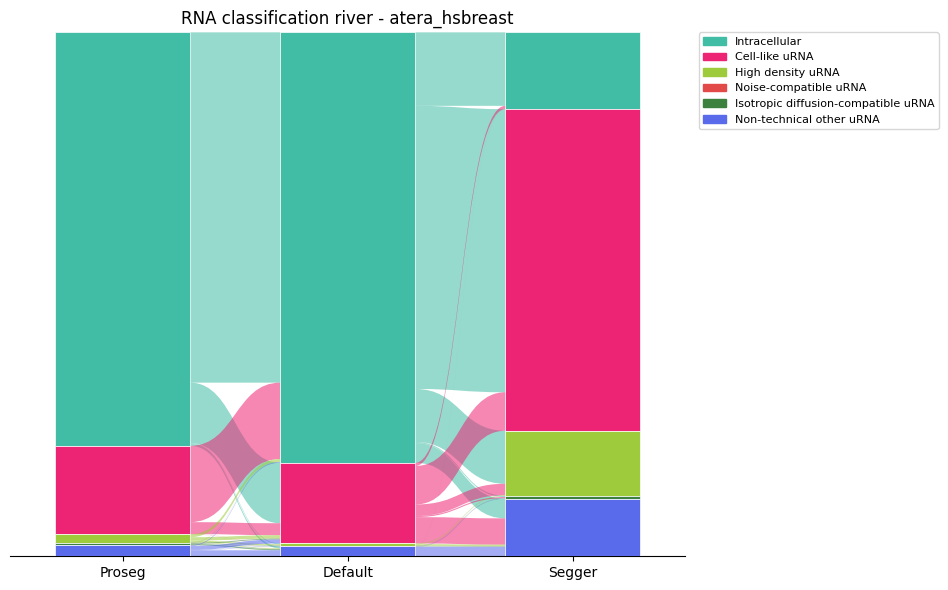

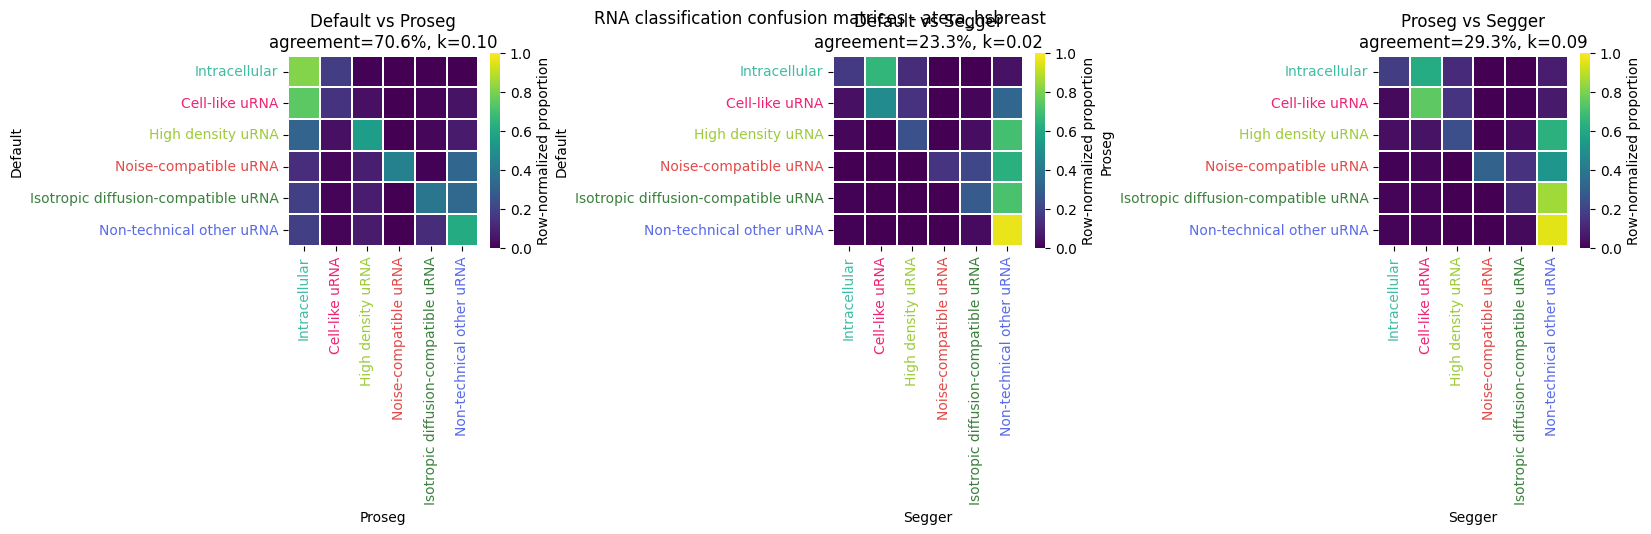

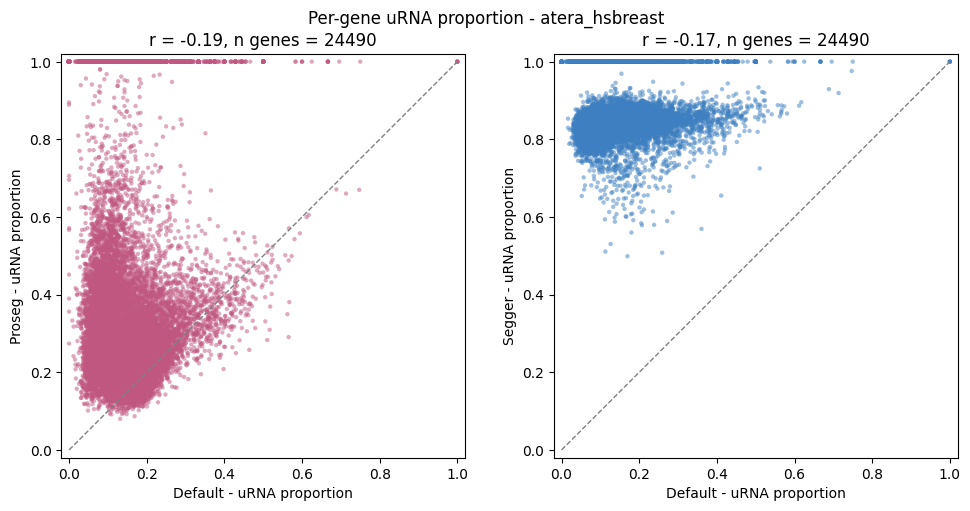

=== cosmx_hgsoc ===


[cosmx_hgsoc] available methods: ['rois', 'rois_proseg', 'rois_segger']
[cosmx_hgsoc] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 251217


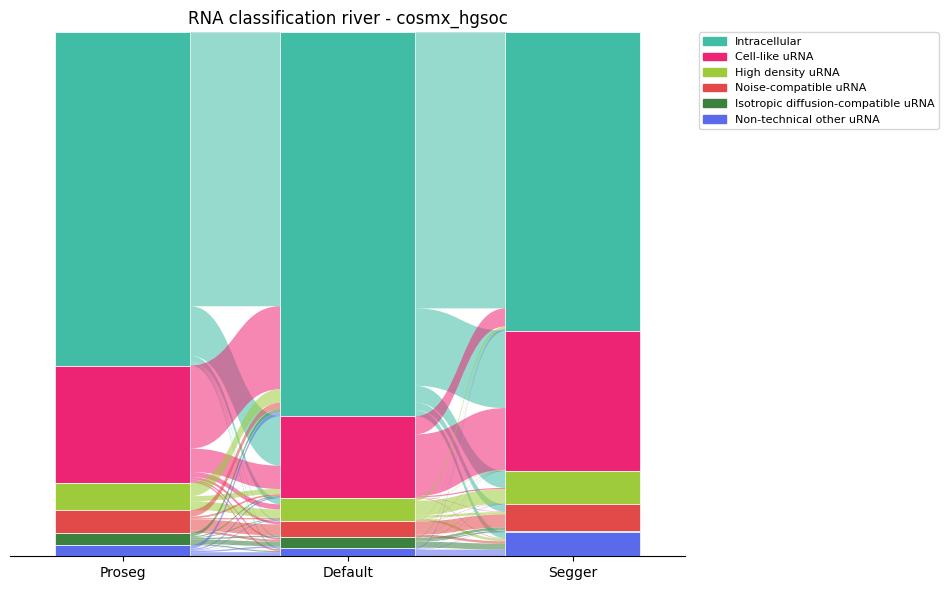

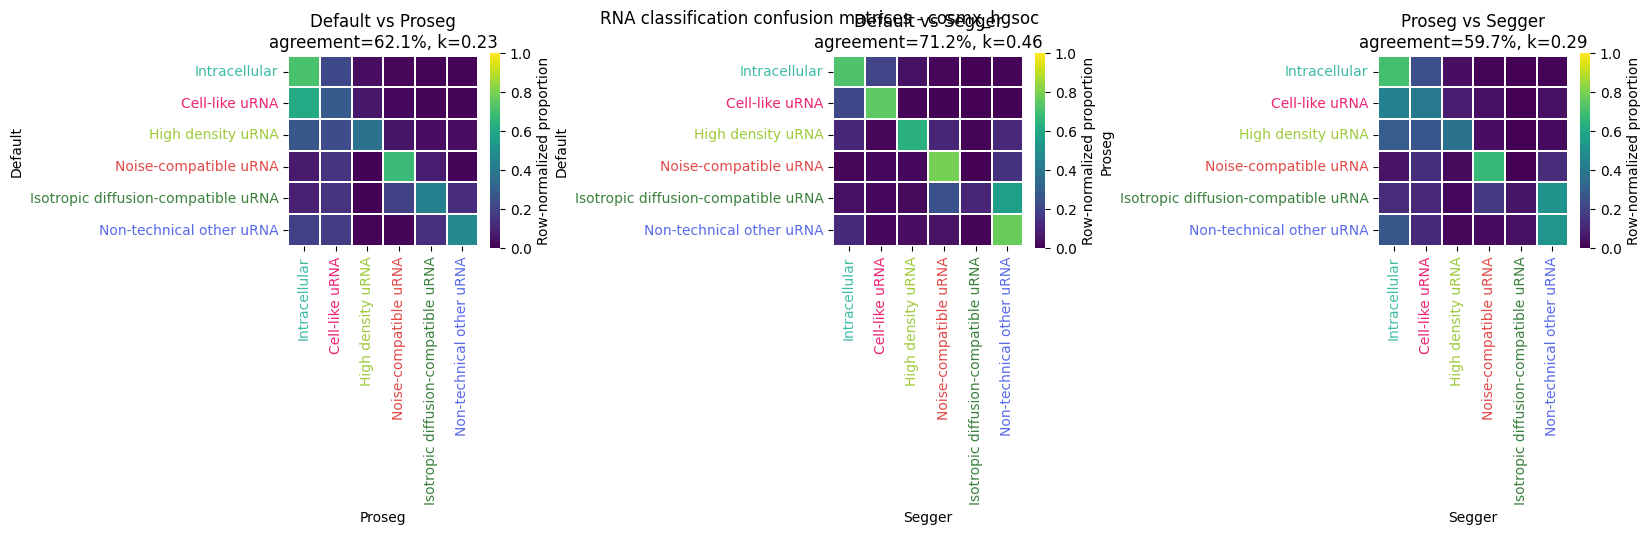

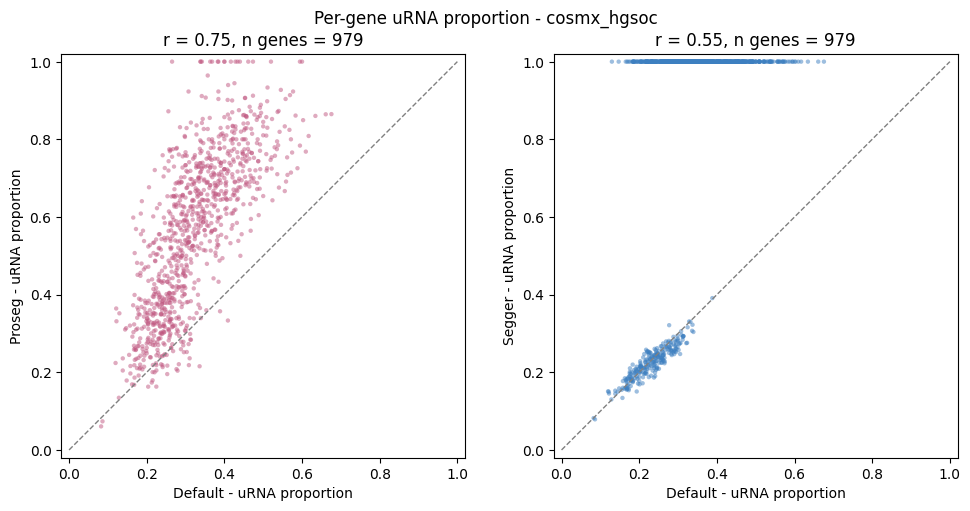

=== cosmx_melanoma ===


[cosmx_melanoma] available methods: ['rois', 'rois_proseg', 'rois_segger']
[cosmx_melanoma] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 3043815


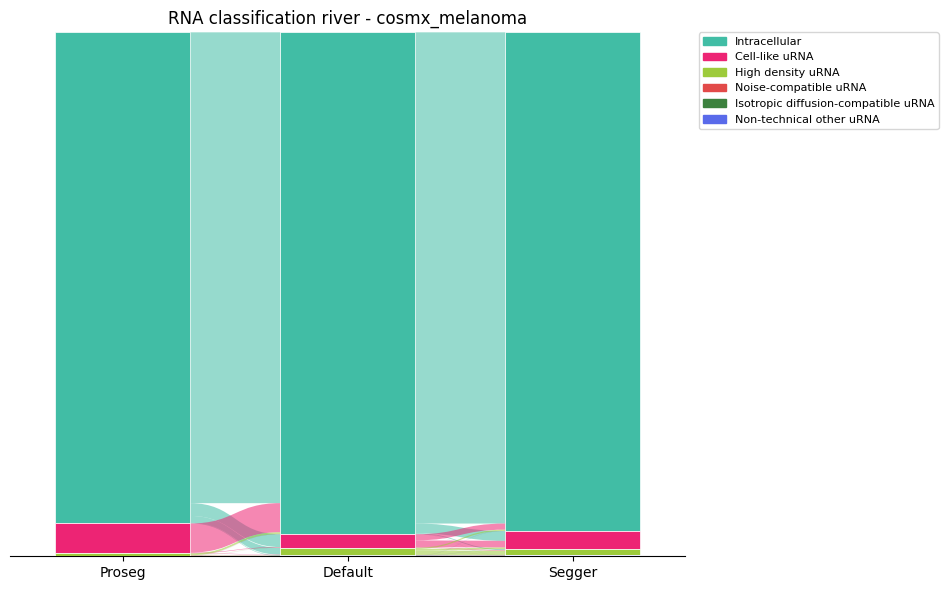

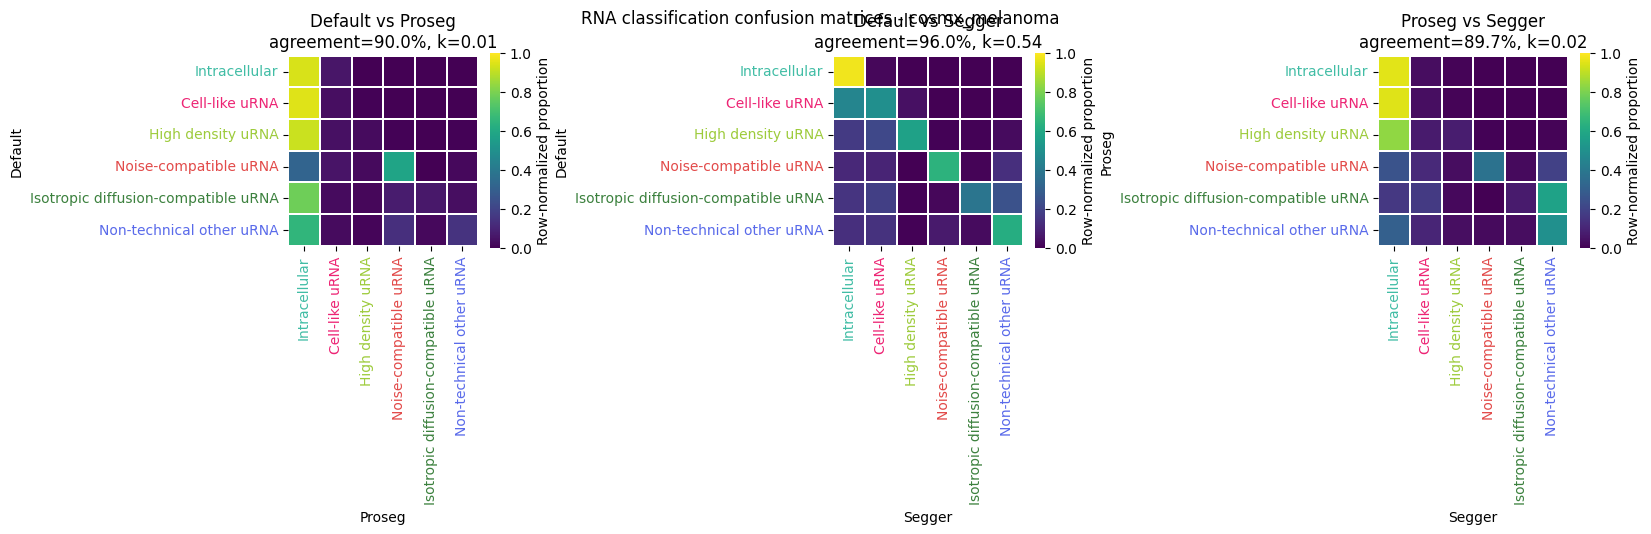

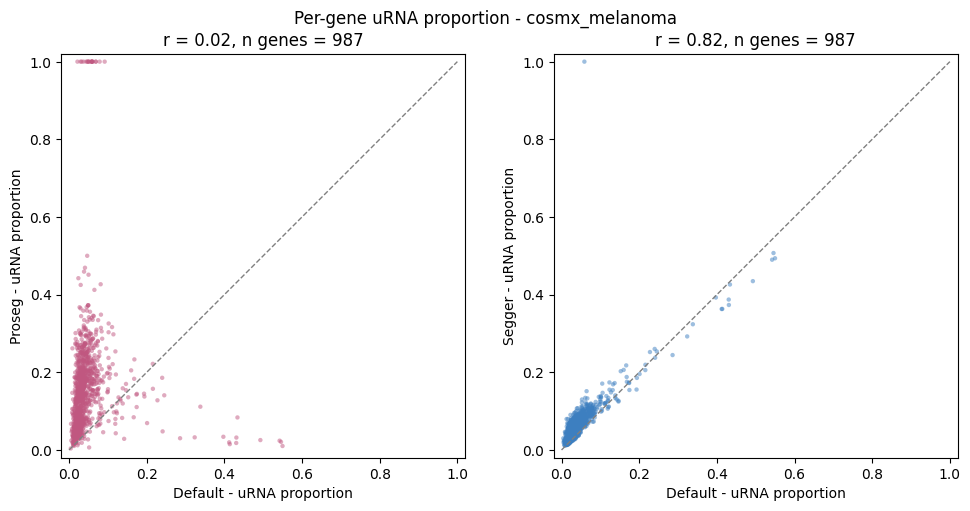

=== cosmx_mousebrain ===


[cosmx_mousebrain] available methods: ['rois', 'rois_proseg', 'rois_segger']
[cosmx_mousebrain] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 19013669


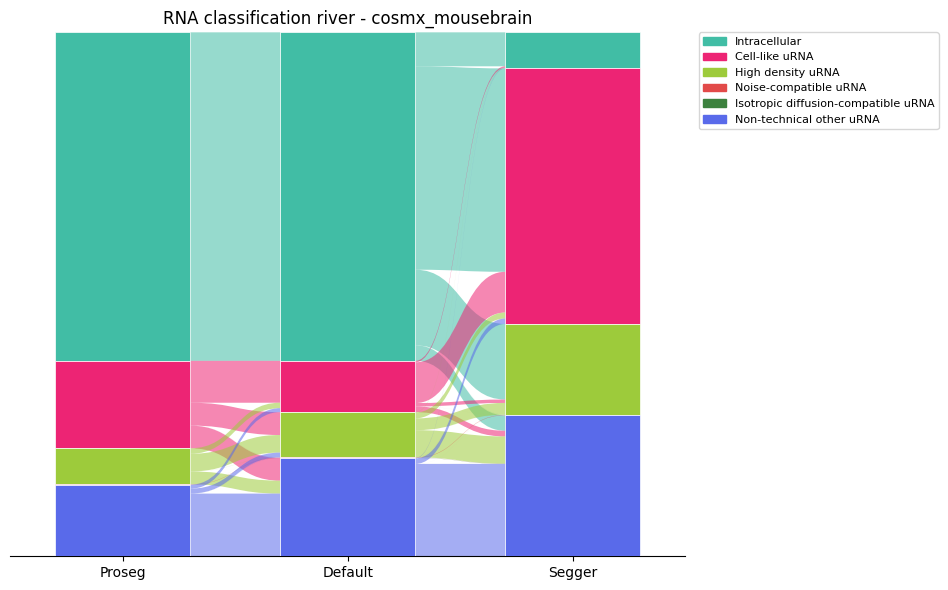

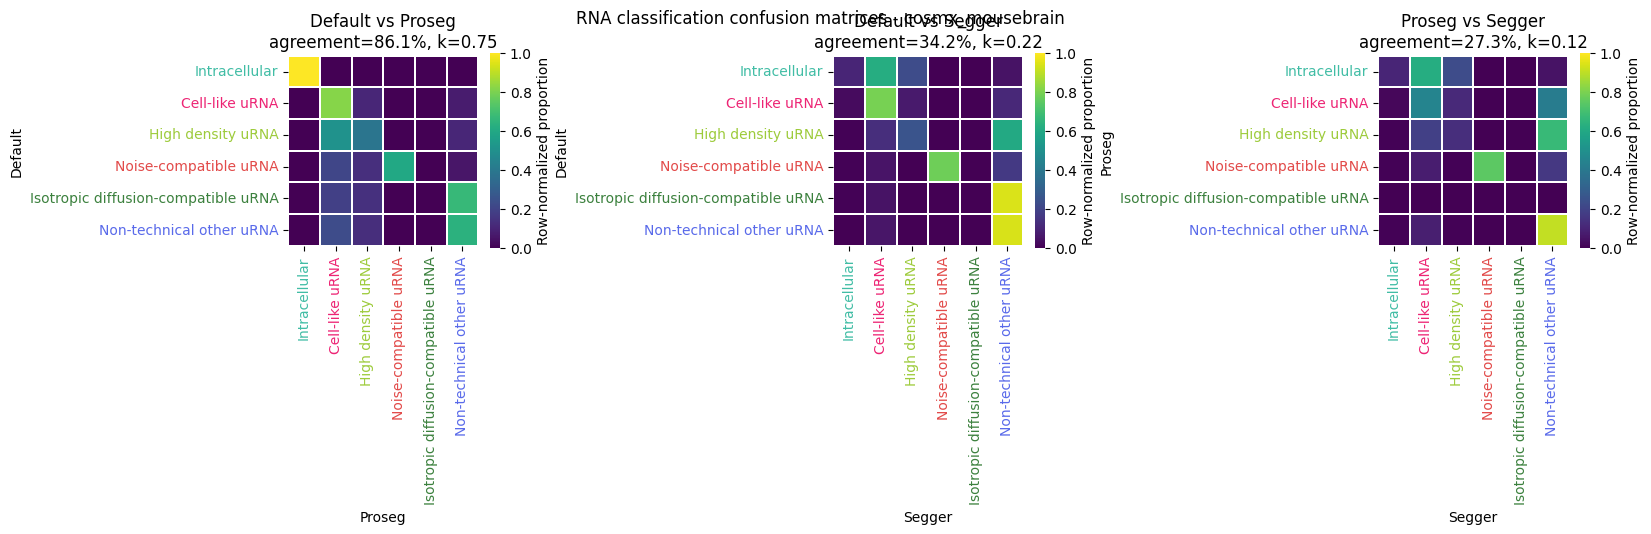

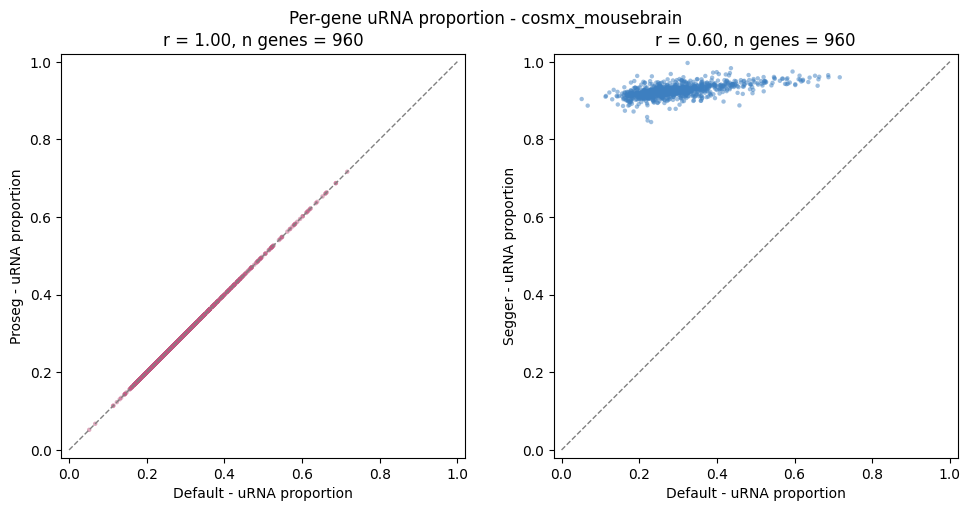

=== cosmx_pancreas ===


[cosmx_pancreas] Skipped - default segmentation missing or <2 methods available
=== cosmx_stomach ===


[cosmx_stomach] available methods: ['rois', 'rois_proseg', 'rois_segger']
[cosmx_stomach] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 853995


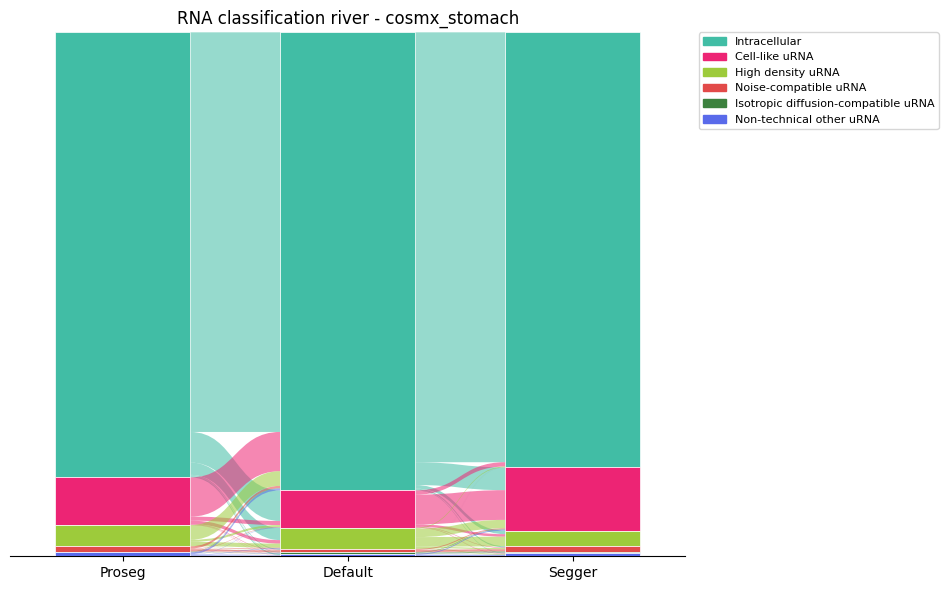

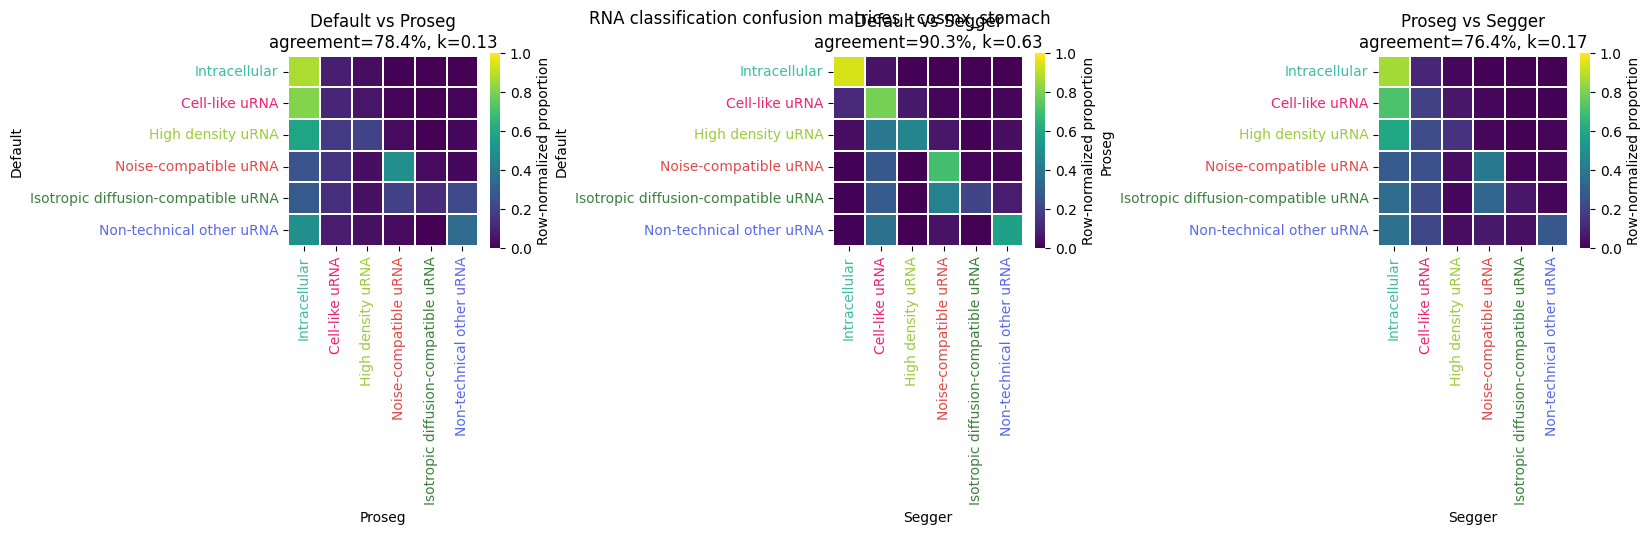

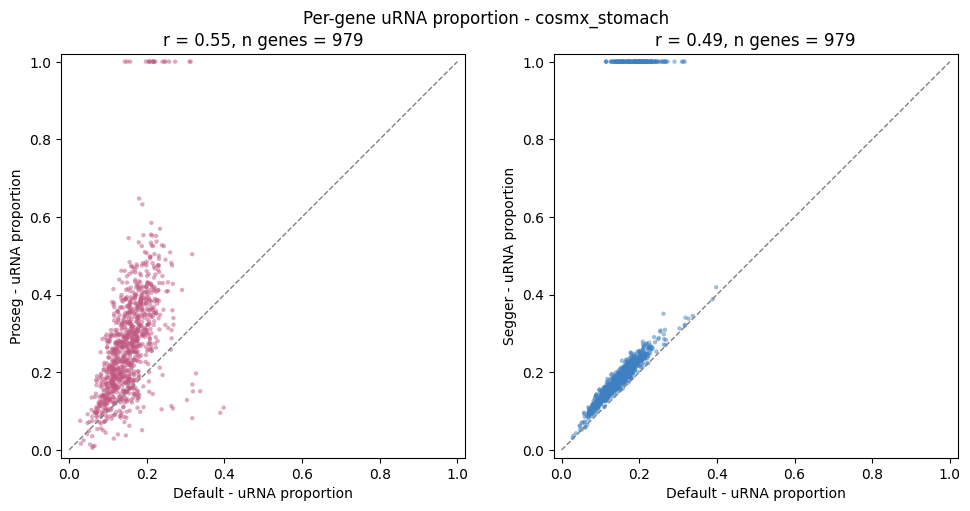

=== merscope_hsbrain ===


[merscope_hsbrain] available methods: ['rois', 'rois_proseg', 'rois_segger']
[merscope_hsbrain] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 305050


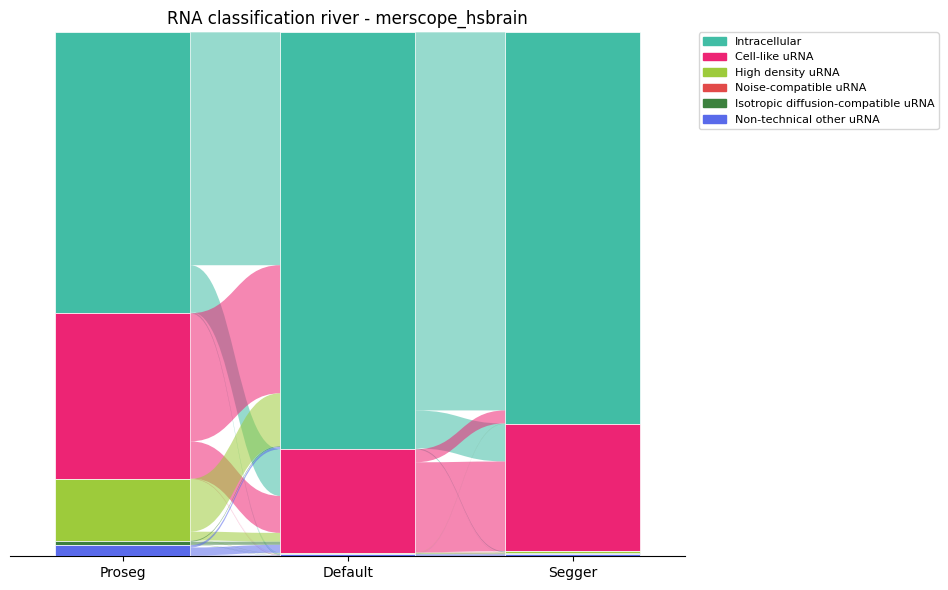

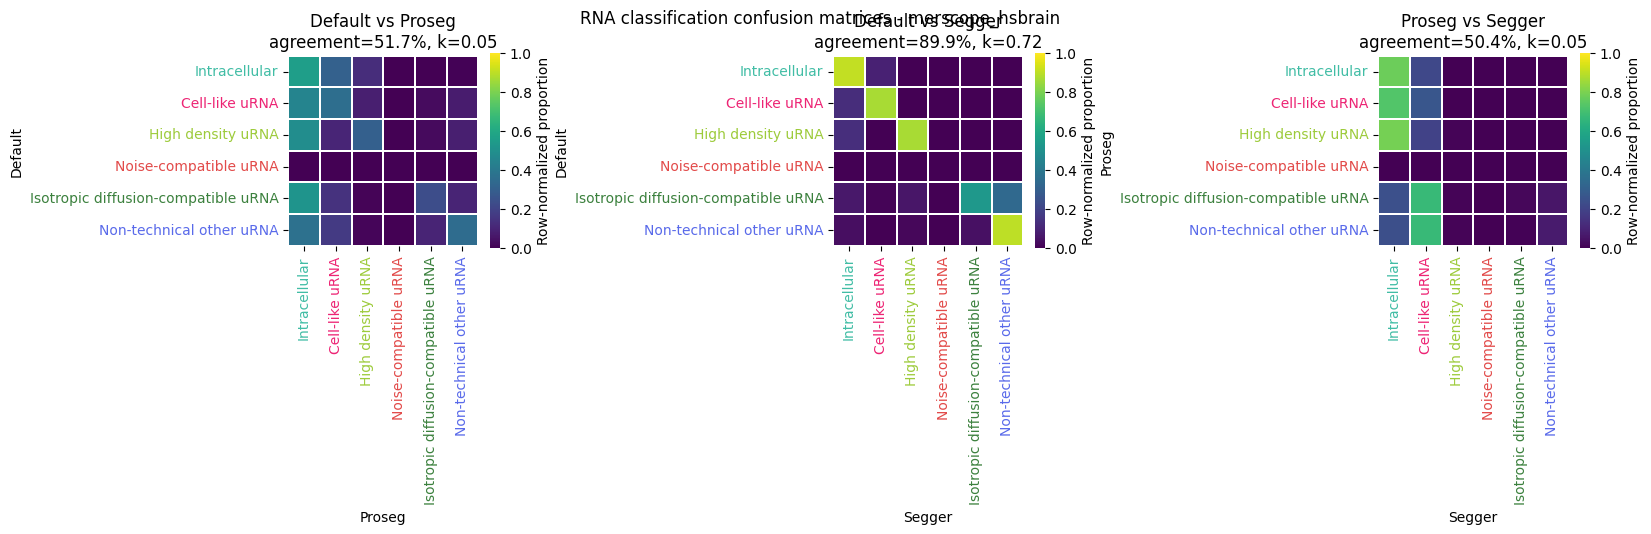

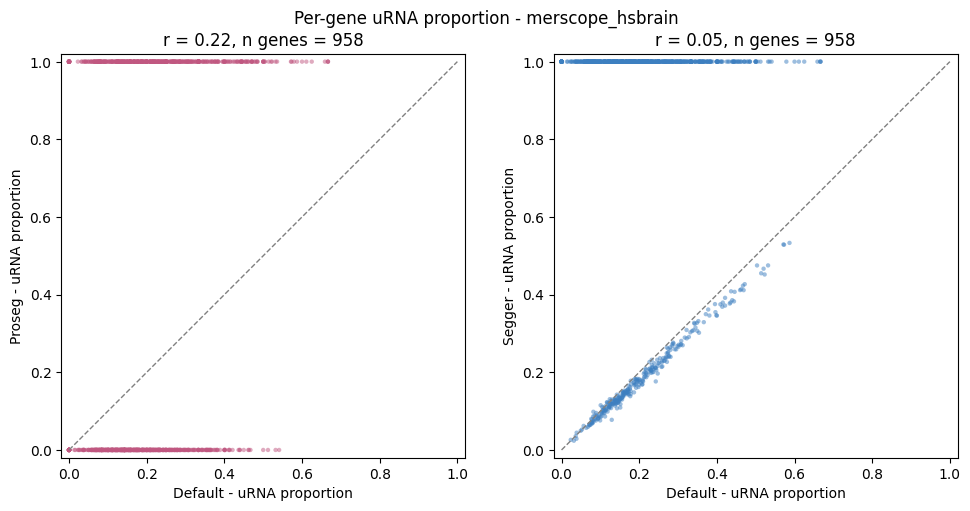

=== merscope_hsuterine ===


[merscope_hsuterine] available methods: ['rois', 'rois_proseg', 'rois_segger']
[merscope_hsuterine] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 6656782


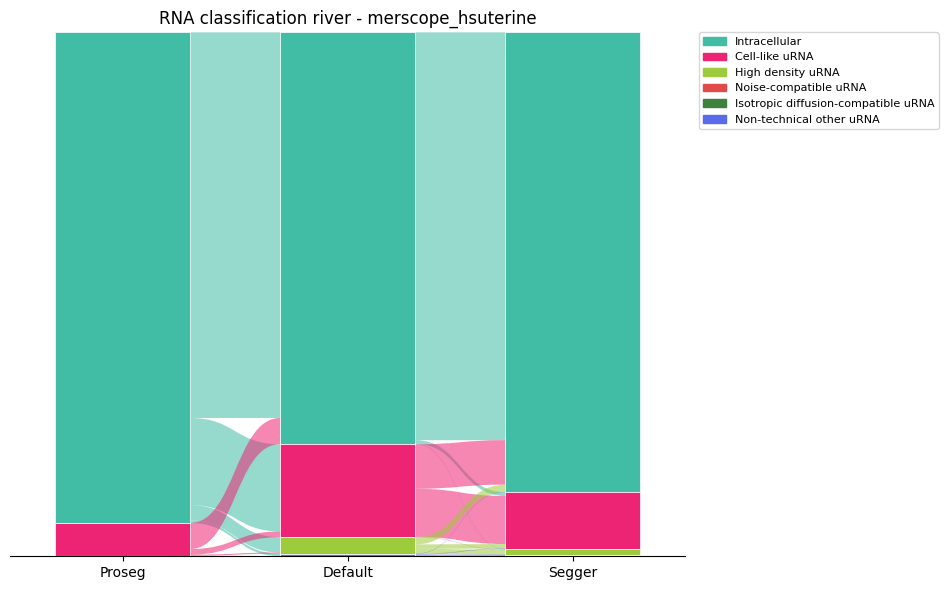

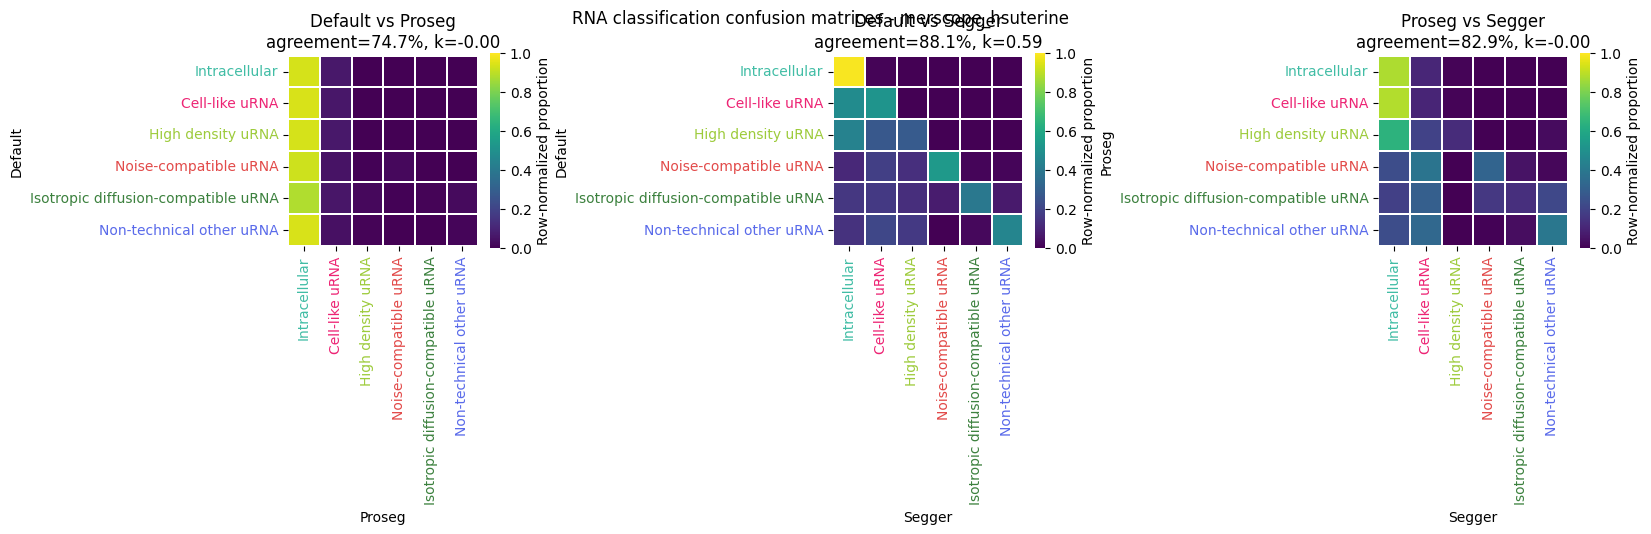

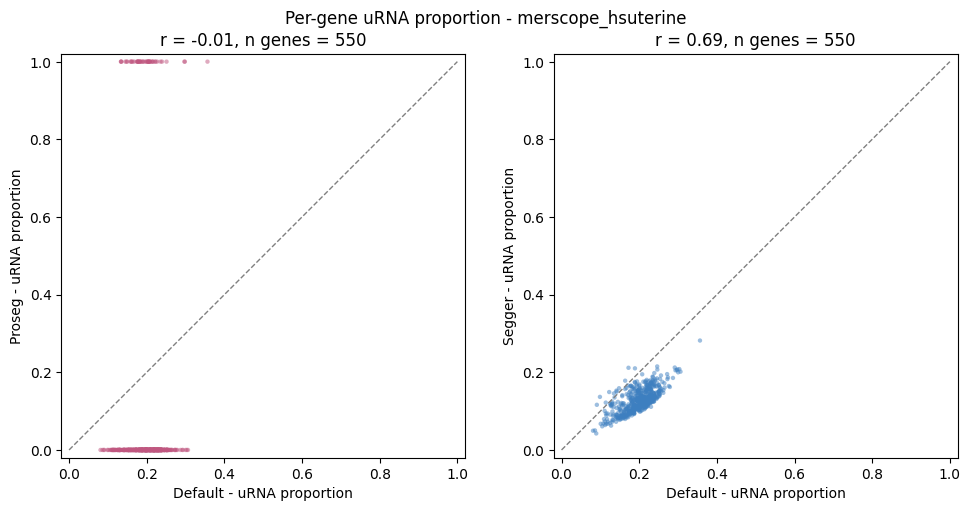

=== xenium_hsfemur ===


[xenium_hsfemur] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_hsfemur] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 1347715


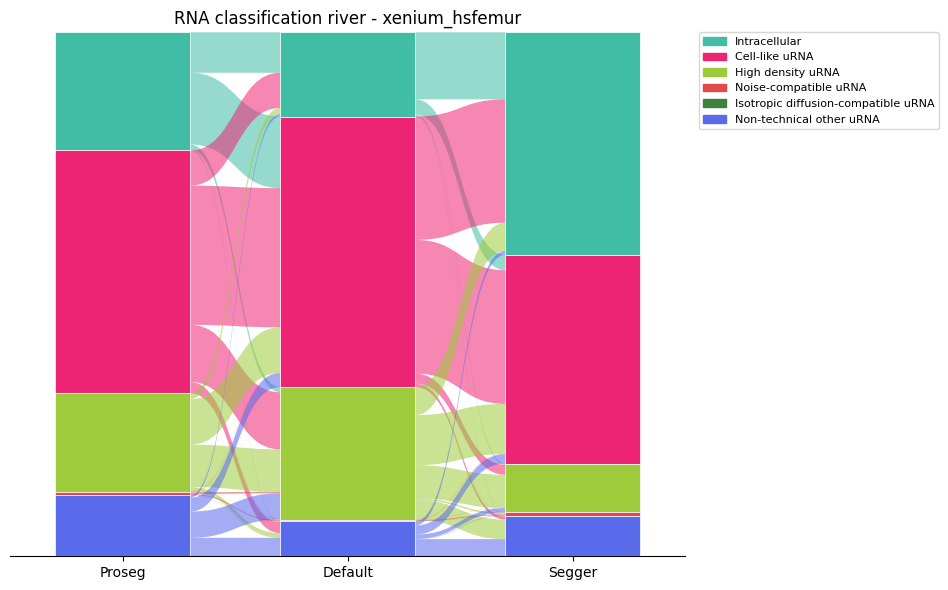

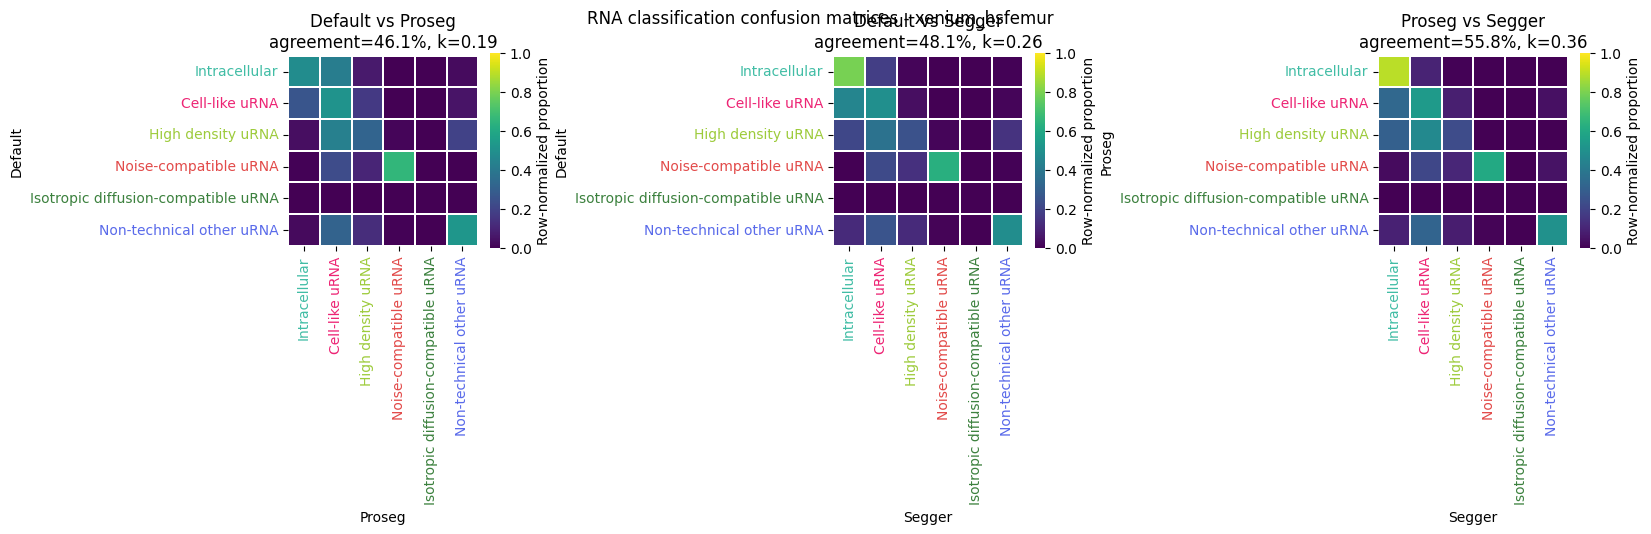

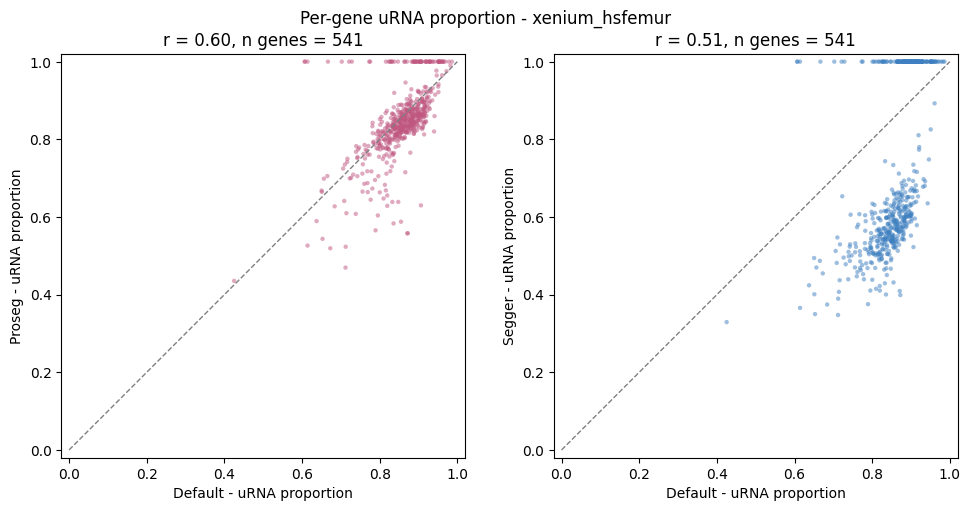

=== xenium_hsheart ===


[xenium_hsheart] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_hsheart] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 2451466


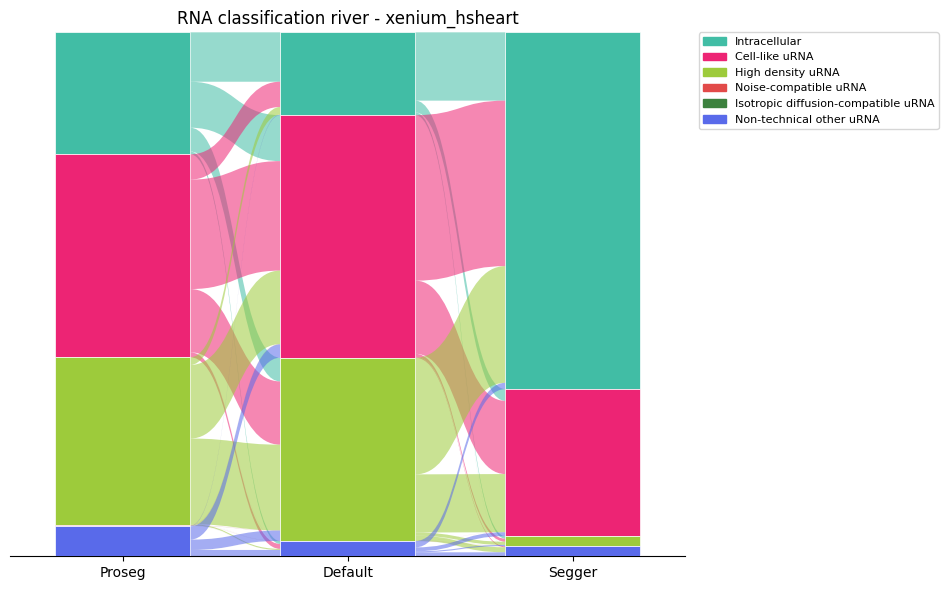

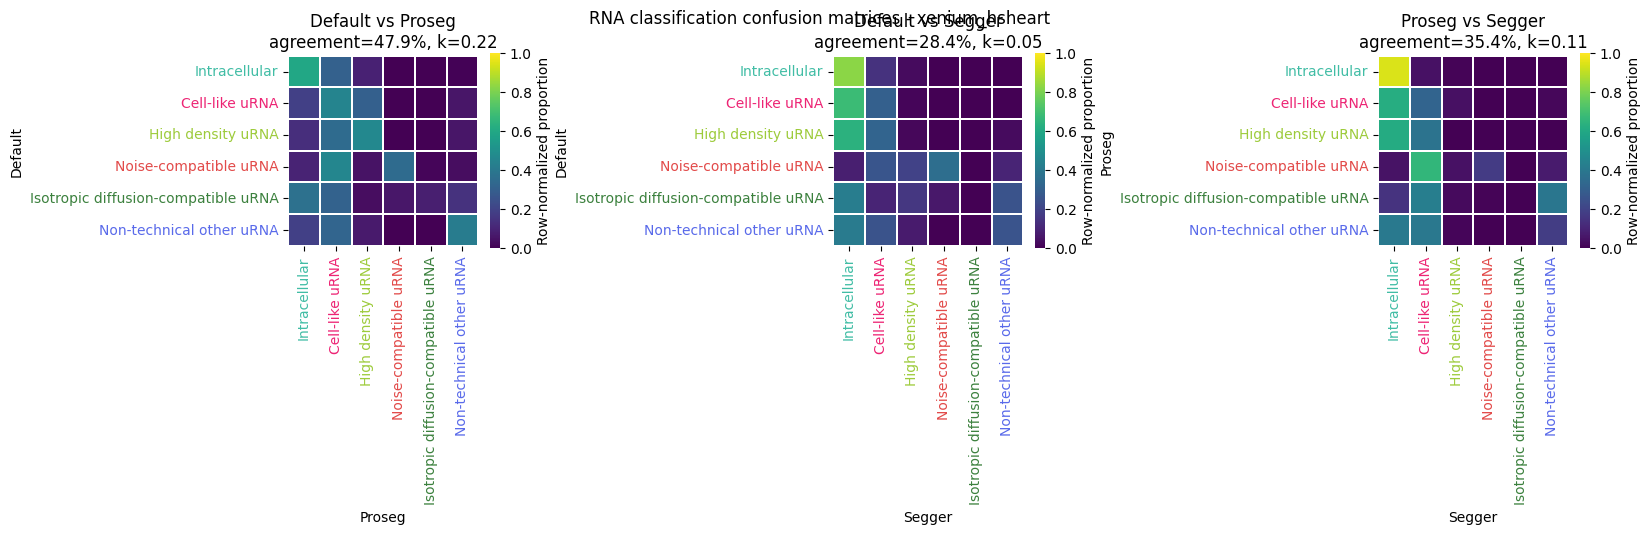

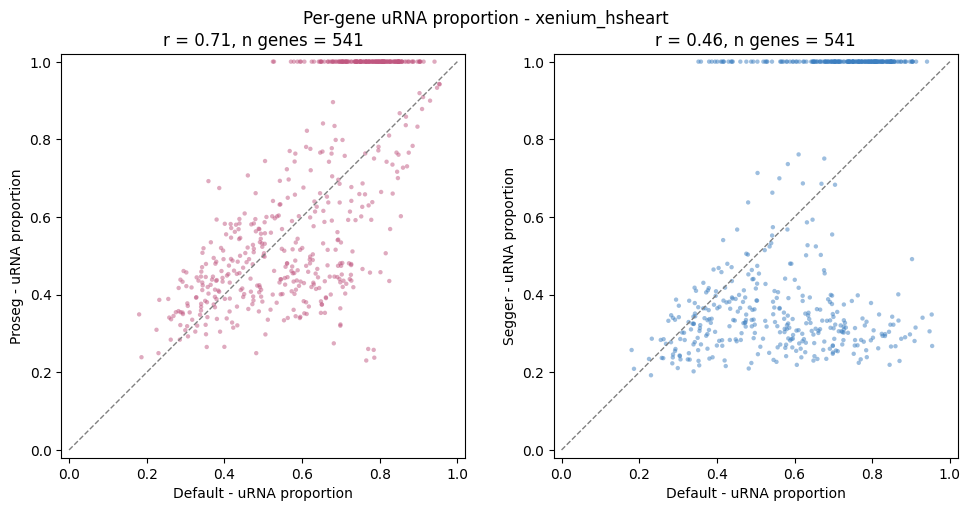

=== xenium_hsprostate ===


[xenium_hsprostate] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_hsprostate] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 2184955


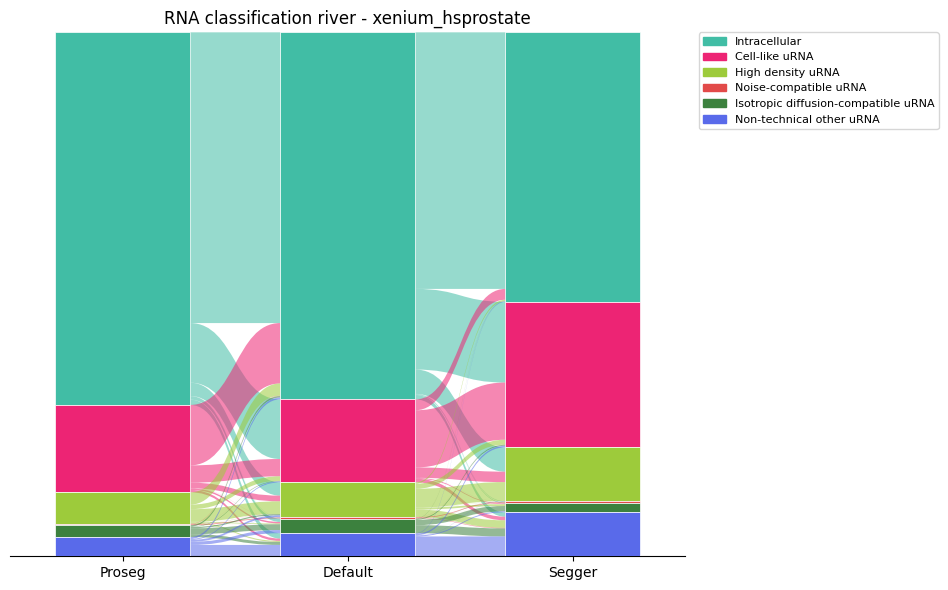

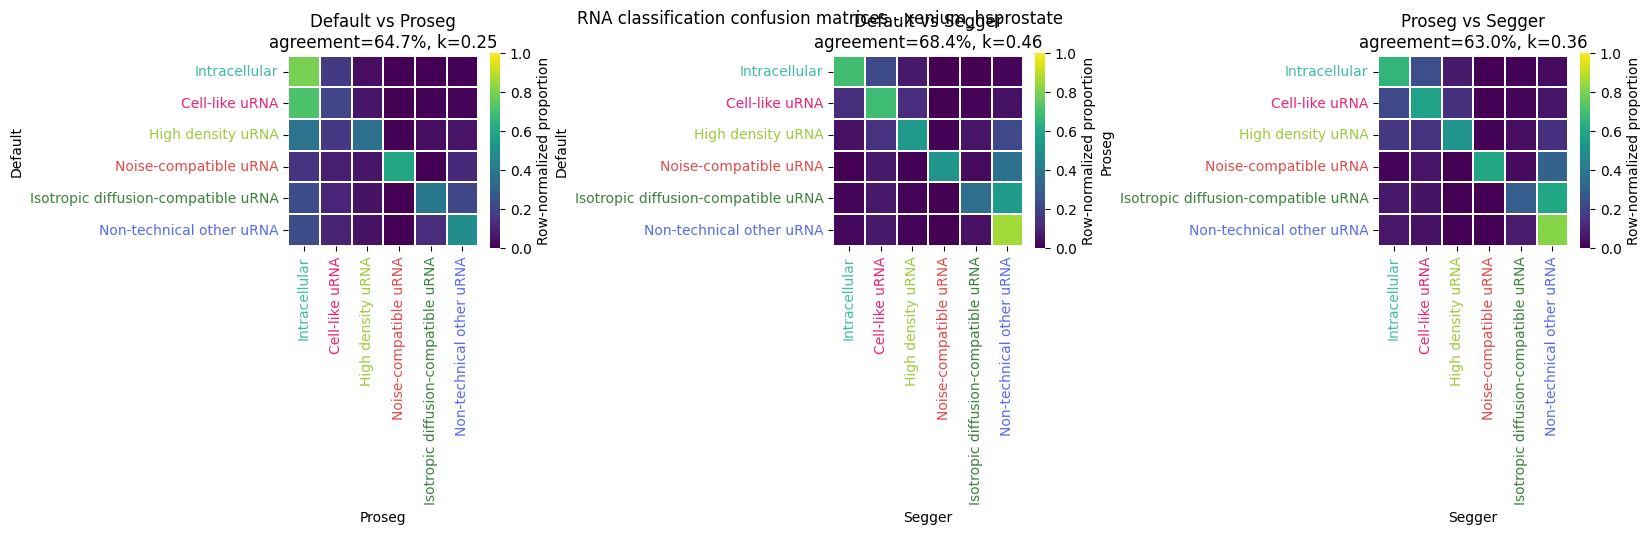

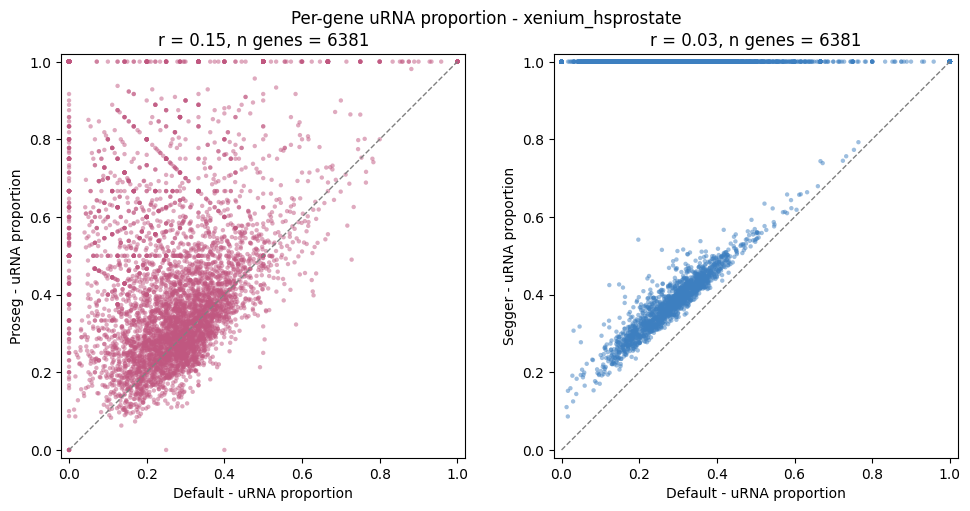

=== xenium_hsputamen ===


[xenium_hsputamen] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_hsputamen] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 744458


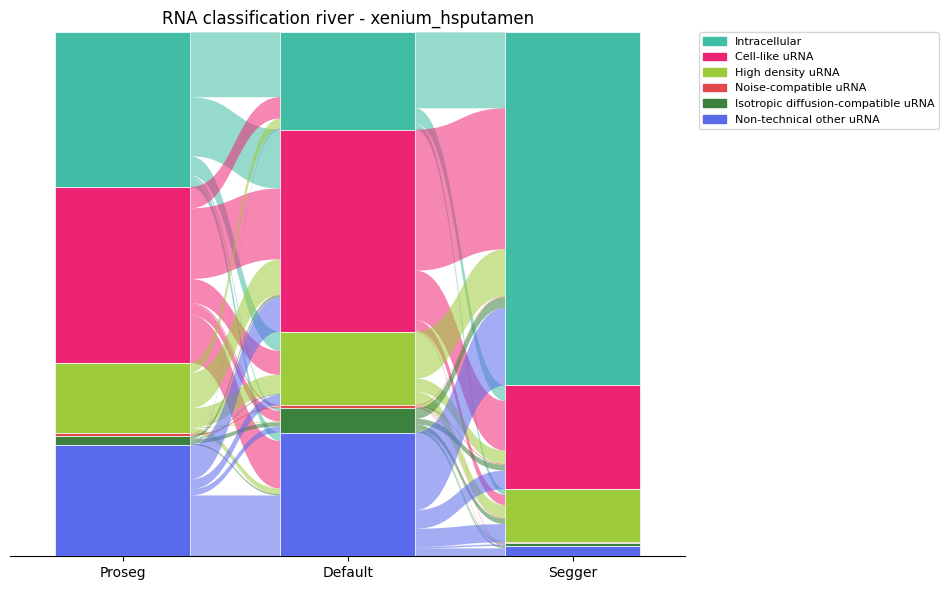

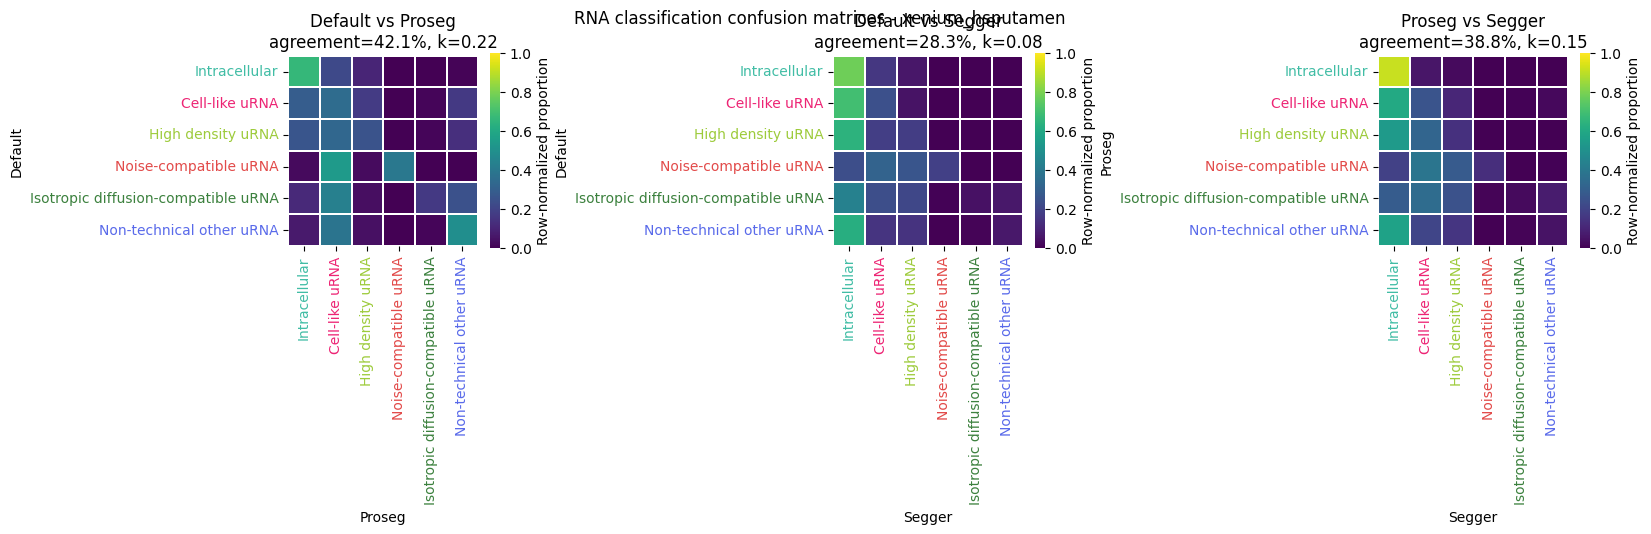

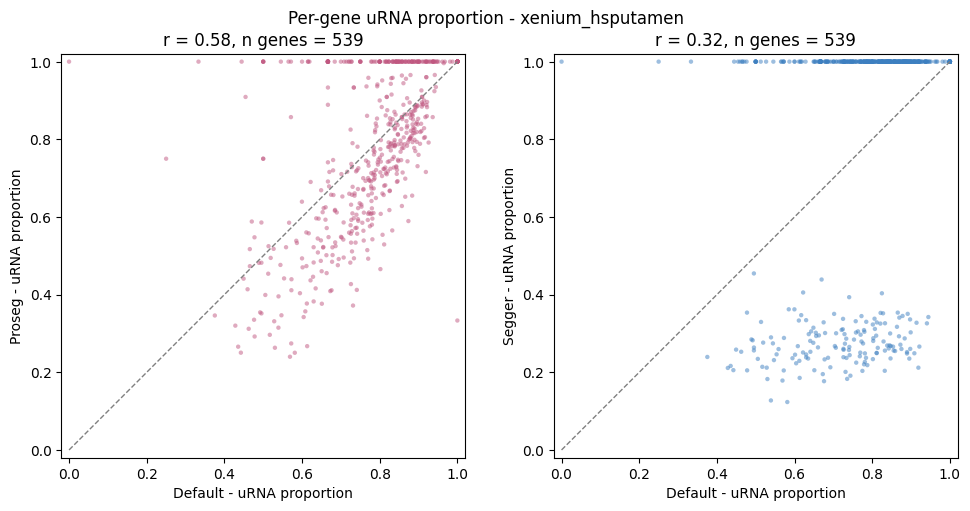

=== xenium_hsskin_5k ===


[xenium_hsskin_5k] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_hsskin_5k] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 4644030


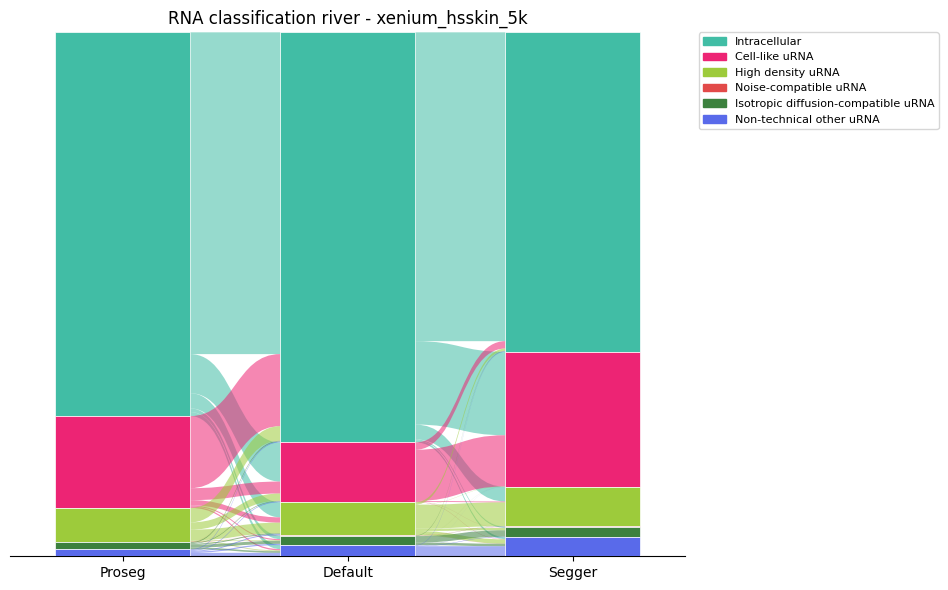

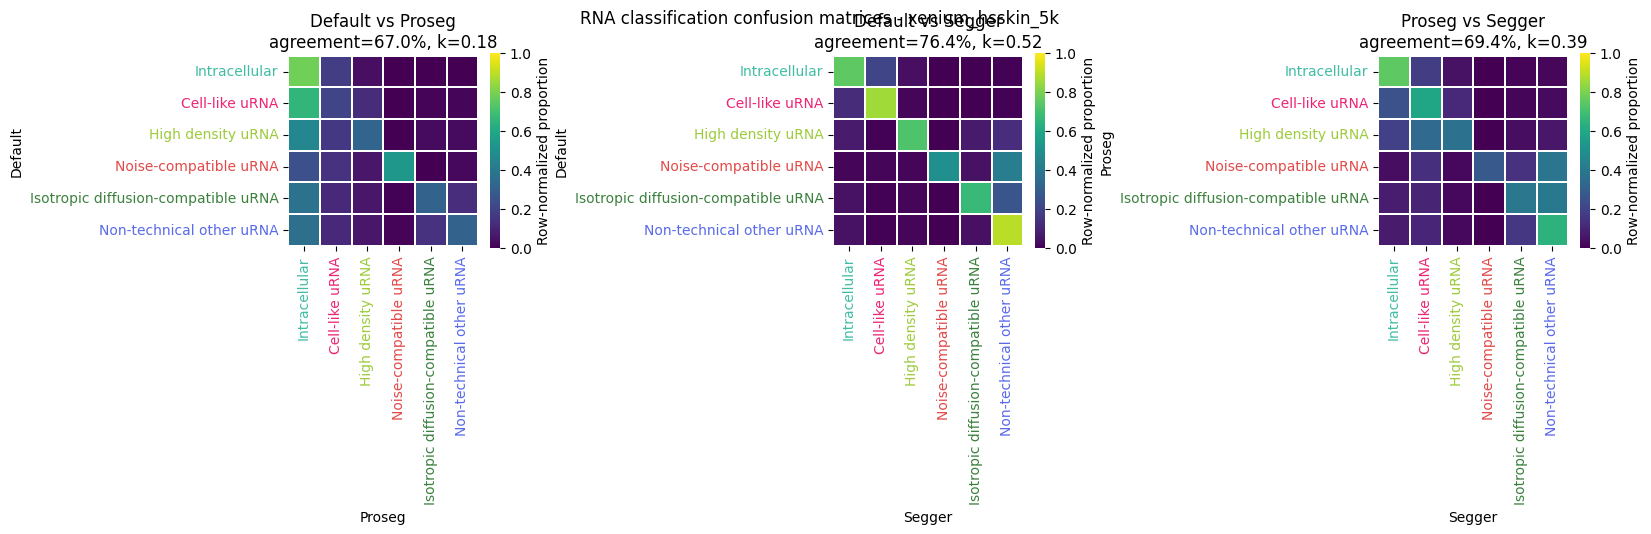

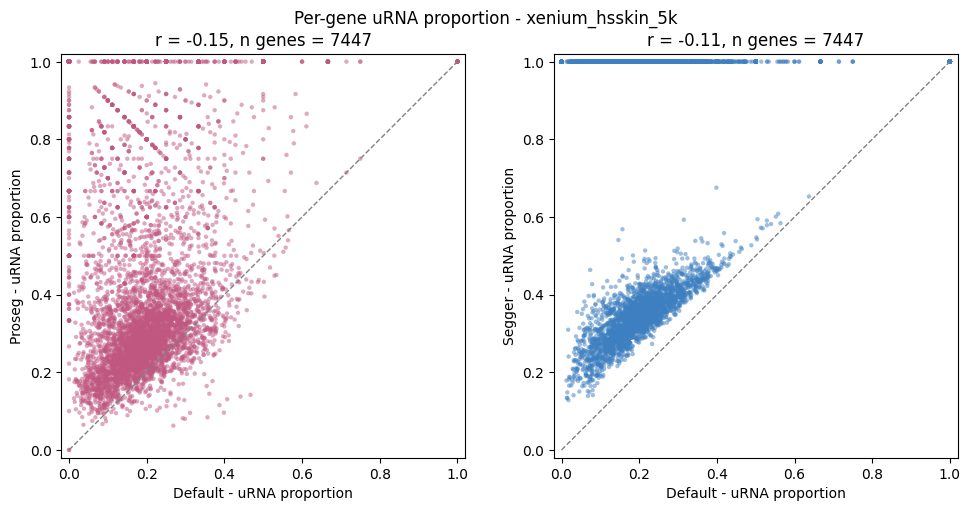

=== xenium_msbrain_300 ===


[xenium_msbrain_300] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_msbrain_300] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 8906974


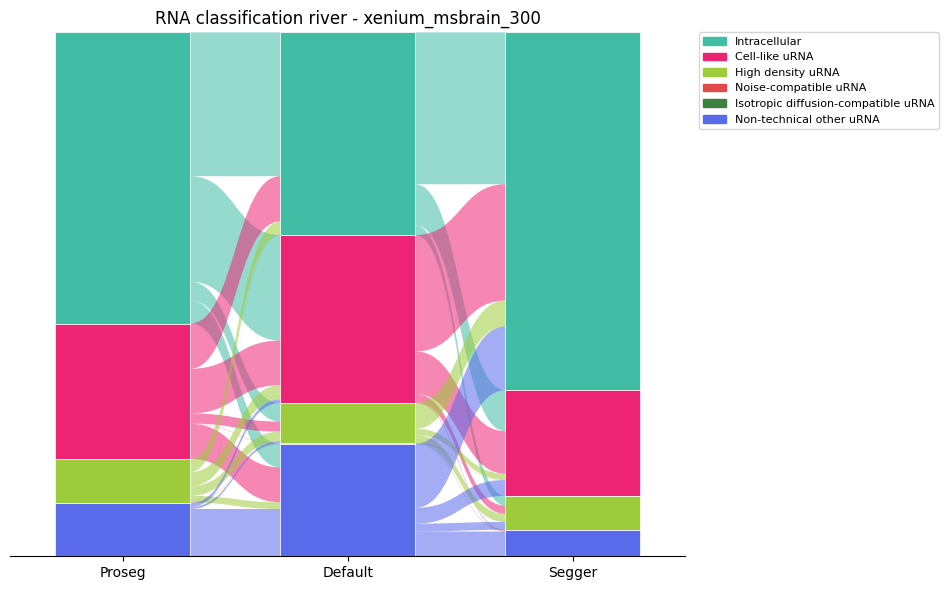

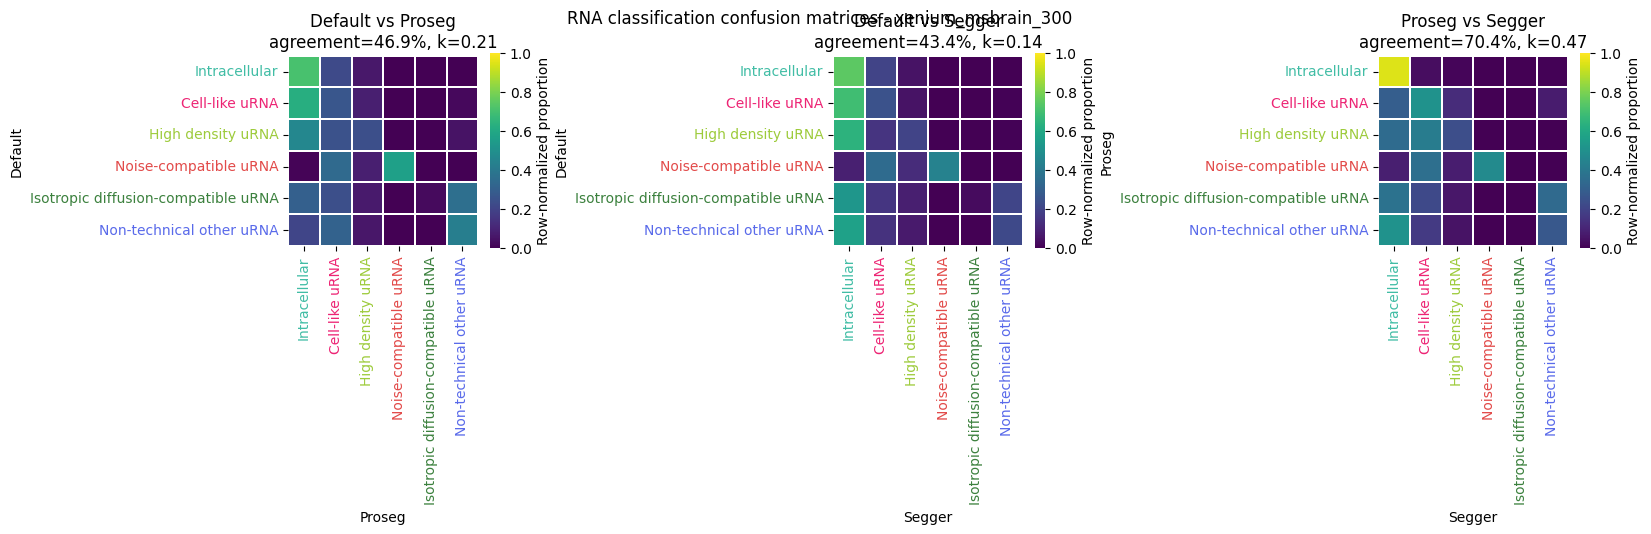

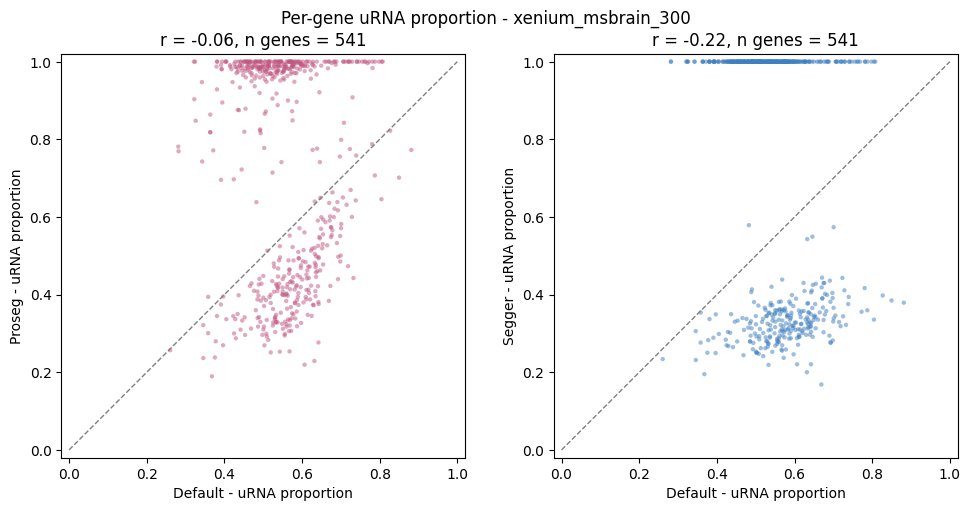

=== xenium_msbrain_5k ===


[xenium_msbrain_5k] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_msbrain_5k] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 23790756


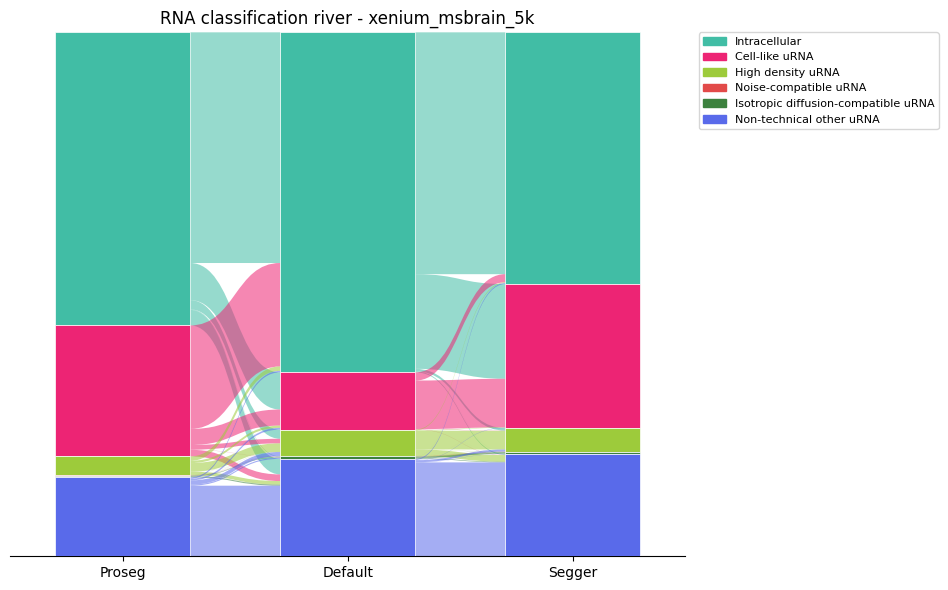

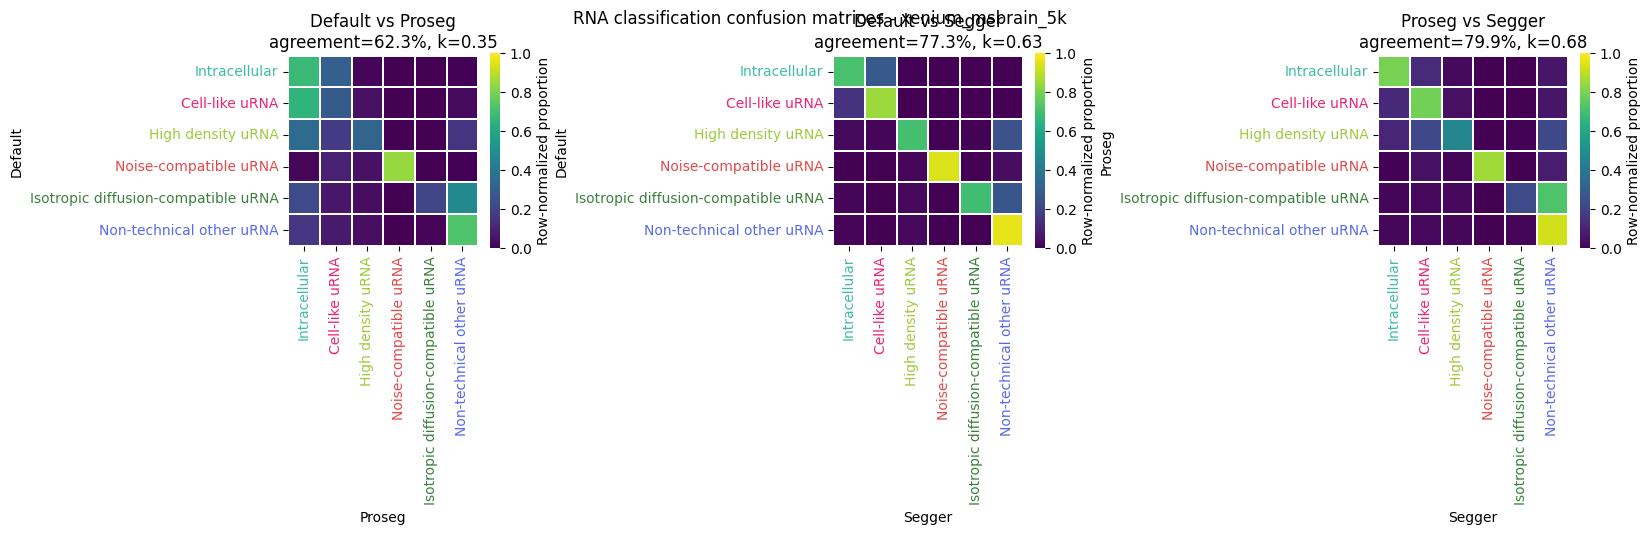

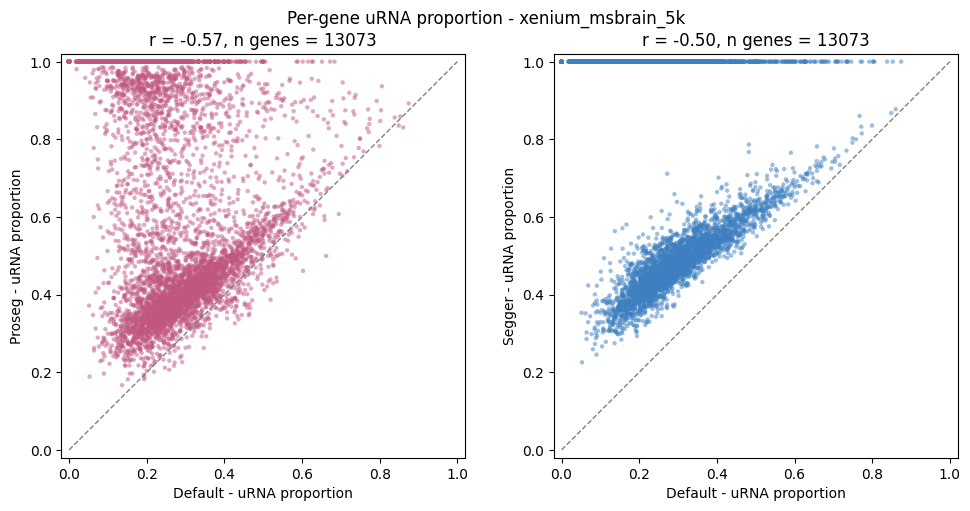

=== xenium_msbrain_5k_large ===


[xenium_msbrain_5k_large] Skipped - default segmentation missing or <2 methods available
=== xenium_mscolon_5k ===


[xenium_mscolon_5k] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_mscolon_5k] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 12204167


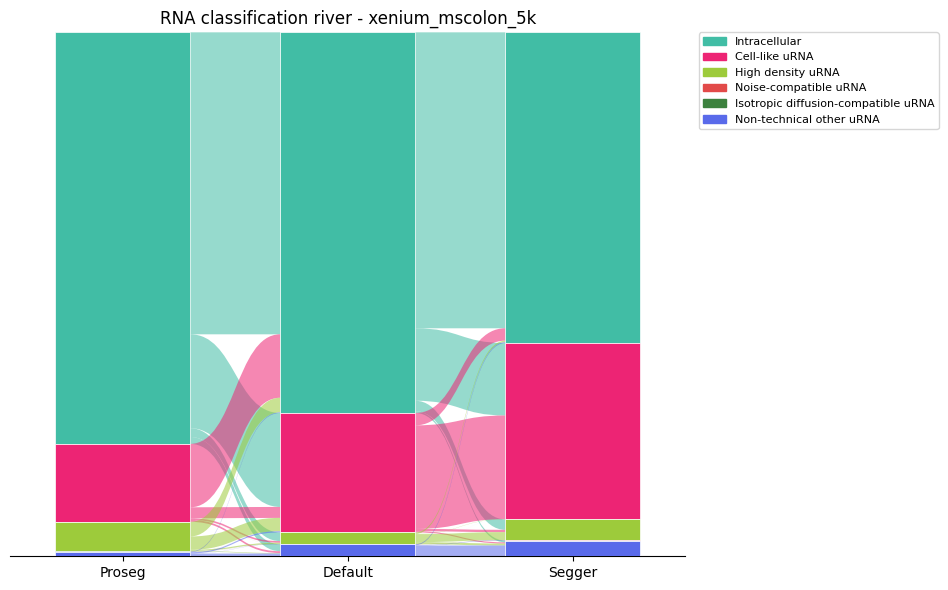

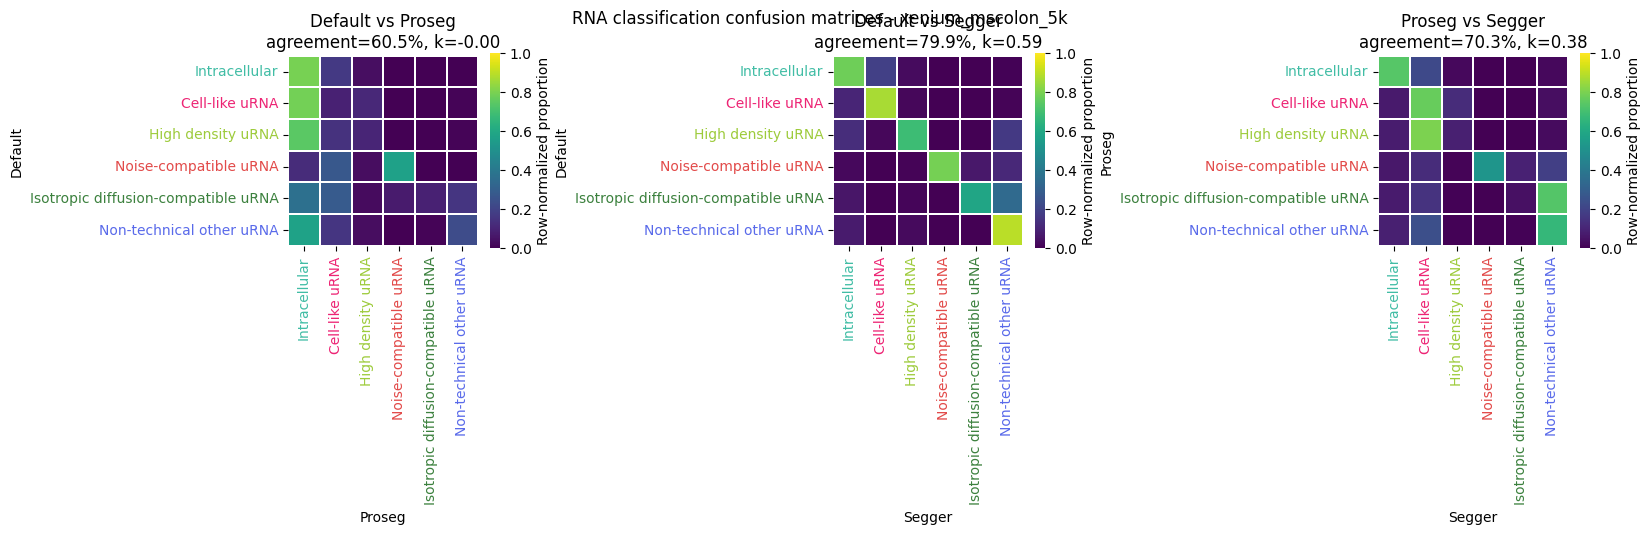

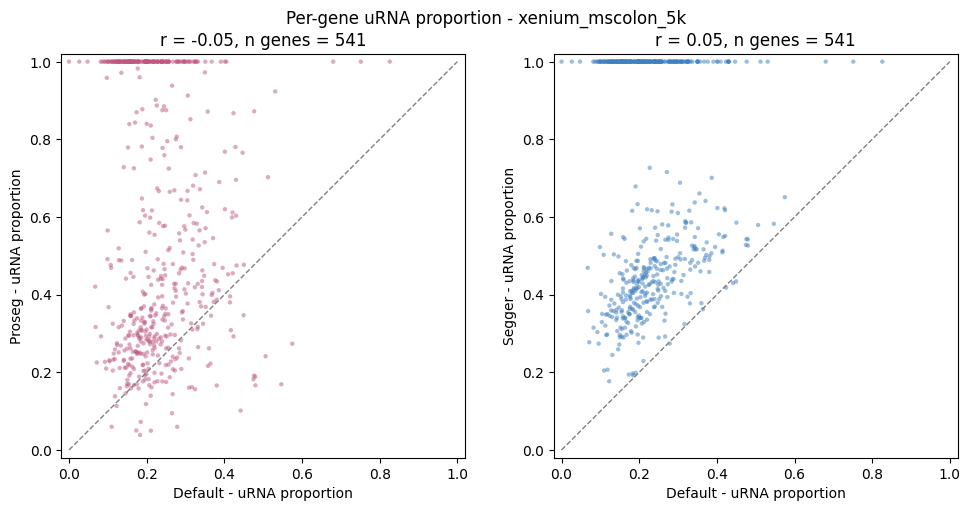

=== xenium_opsc_5k ===


[xenium_opsc_5k] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_opsc_5k] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 63989200


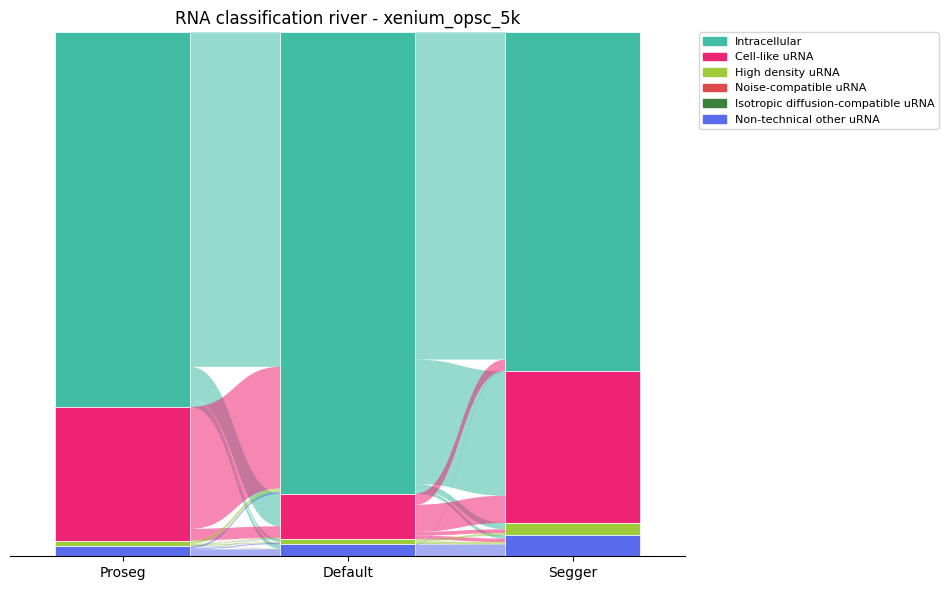

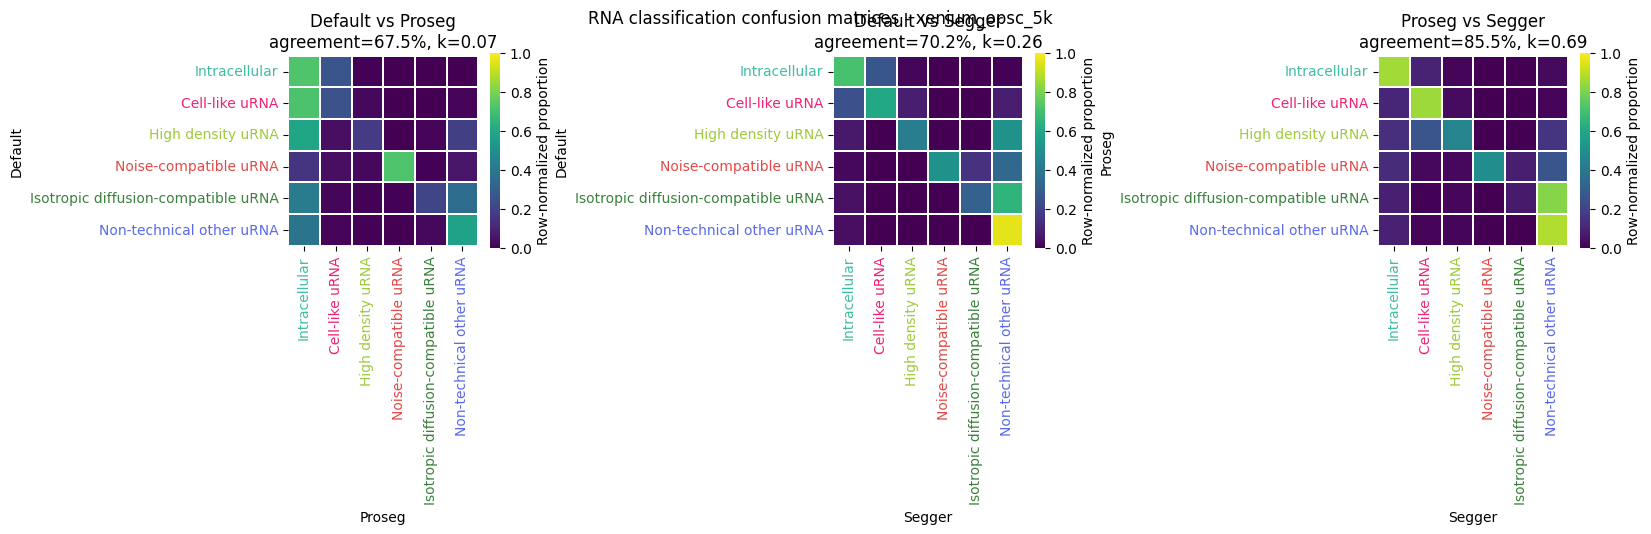

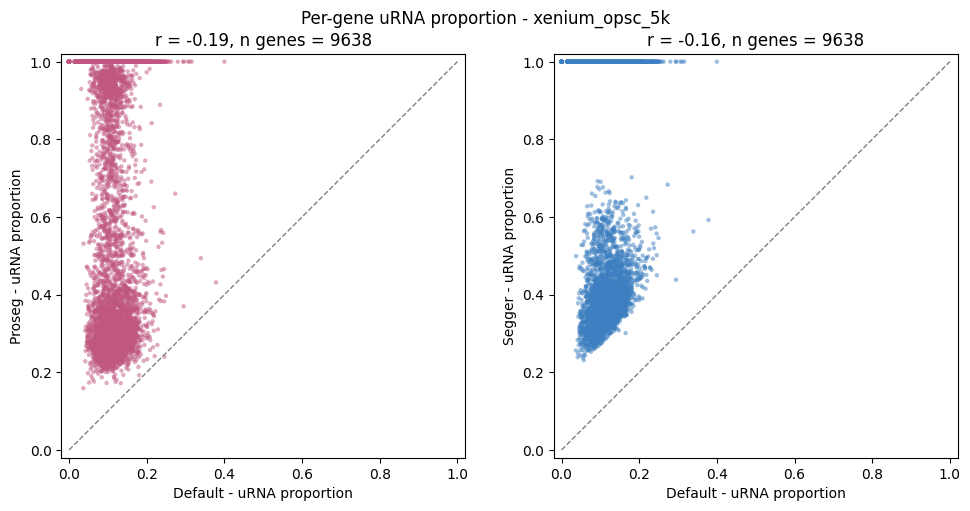

=== xenium_opsc_v1 ===


[xenium_opsc_v1] available methods: ['rois', 'rois_proseg', 'rois_segger']
[xenium_opsc_v1] shared transcripts across ['rois', 'rois_proseg', 'rois_segger']: 21912652


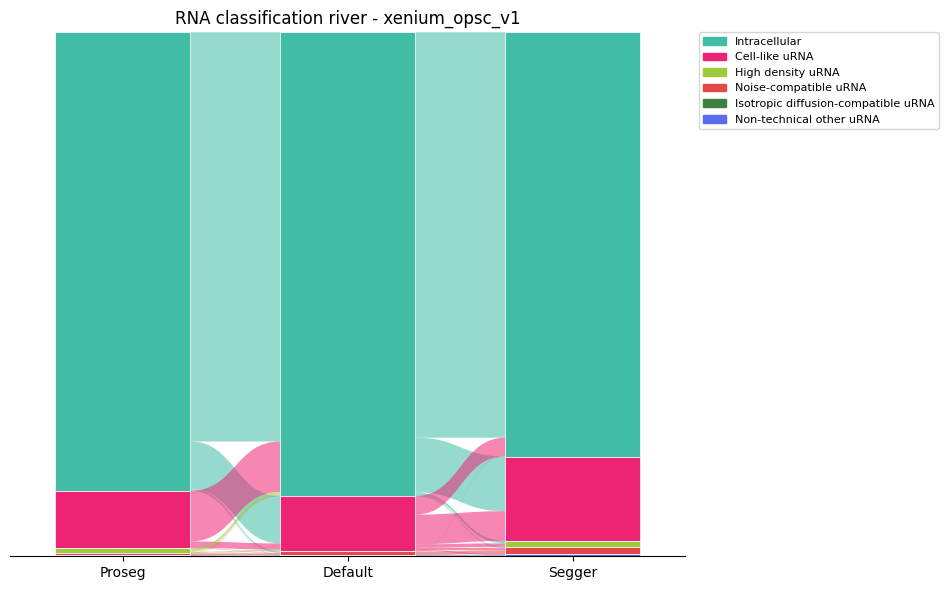

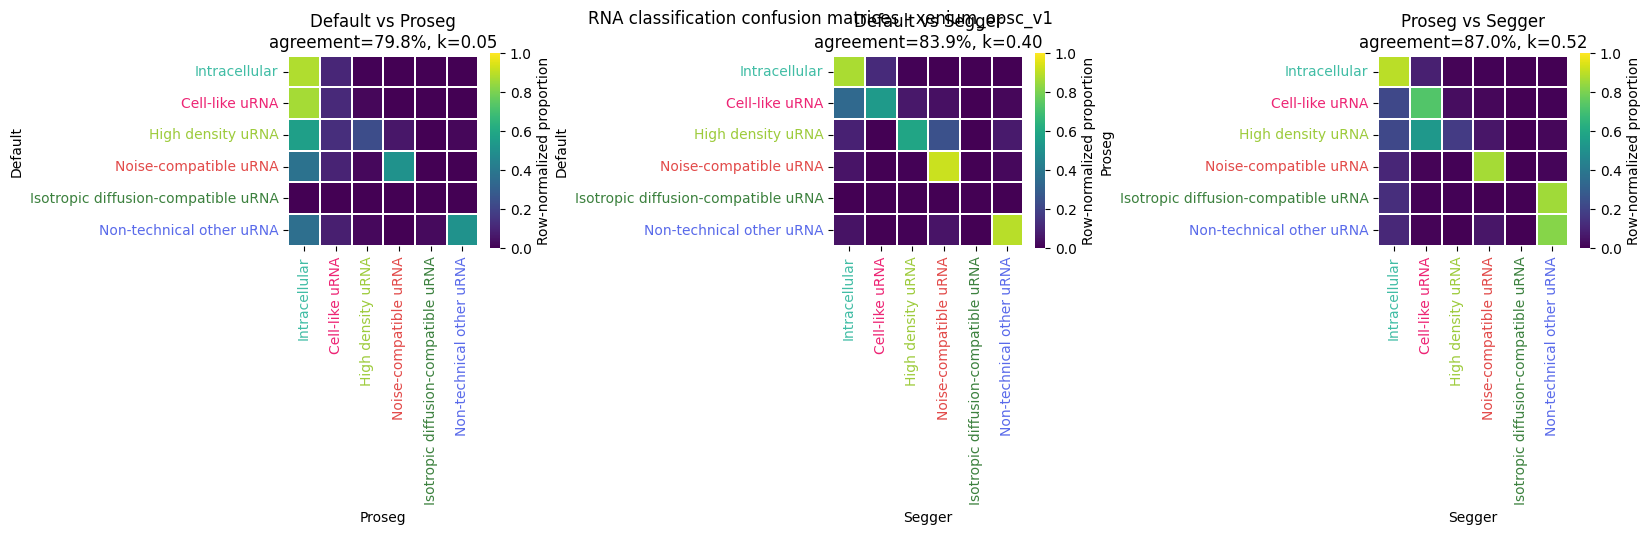

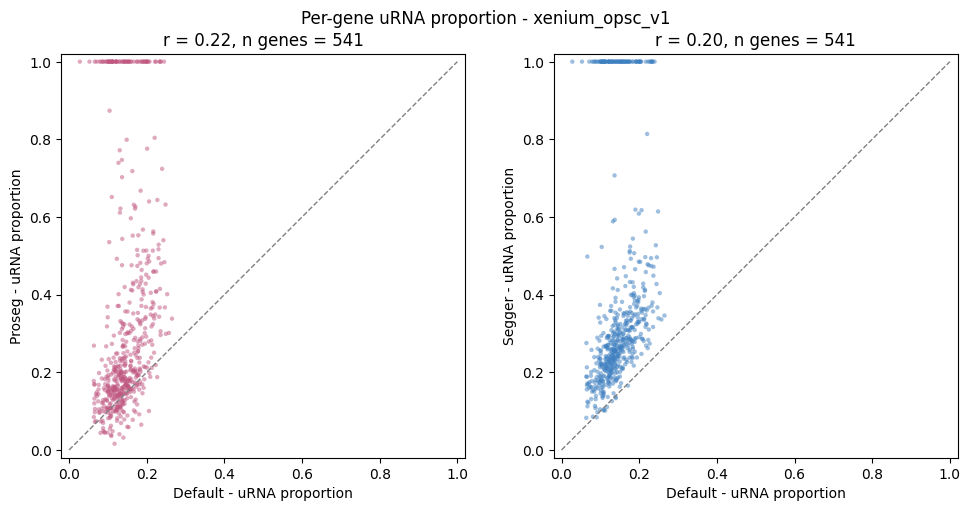

=== xenium_rcc ===
[rois/xenium_rcc] Skipped - failed to load: nothing found at path ''


[xenium_rcc] Skipped - default segmentation missing or <2 methods available
=== xenium_rcc_oldzarr ===


[xenium_rcc_oldzarr] Skipped - default segmentation missing or <2 methods available


,sample,method_a,method_b,kappa,agreement,n_transcripts
0,atera_hsbreast,ALL,ALL,NaN,0.160893,55991728
1,atera_hsbreast,rois,rois_proseg,0.095567,0.705874,55991728
2,atera_hsbreast,rois,rois_segger,0.020072,0.233329,55991728
3,atera_hsbreast,rois_proseg,rois_segger,0.089052,0.292777,55991728
4,cosmx_hgsoc,ALL,ALL,NaN,0.490528,251217
...,...,...,...,...,...,...
63,xenium_opsc_5k,rois_proseg,rois_segger,0.687263,0.855397,63989200
64,xenium_opsc_v1,ALL,ALL,NaN,0.762763,21912652
65,xenium_opsc_v1,rois,rois_proseg,0.054452,0.797852,21912652
66,xenium_opsc_v1,rois,rois_segger,0.396742,0.839279,21912652


In [8]:
default_root = os.path.join(base_dir, default_segmentation)
sample_names = sorted(f.name for f in os.scandir(default_root) if f.is_dir())

summary_records = []
per_gene_records = []

for sample in sample_names:
    print(f"=== {sample} ===")
    per_method = {}
    for seg in segmentations:
        res = classify_transcripts(seg, sample)
        if res is not None:
            per_method[seg] = res
        gc.collect()

    if default_segmentation not in per_method or len(per_method) < 2:
        print(f"[{sample}] Skipped - default segmentation missing or <2 methods available")
        per_method.clear()
        gc.collect()
        continue

    # Row order is only guaranteed identical when every method has the same transcript count;
    # further verify with an elementwise x/y check and drop any method that fails it, rather
    # than silently joining misaligned rows
    ref_seg = default_segmentation
    ref = per_method[ref_seg]
    available_methods = [ref_seg]
    for seg in segmentations:
        if seg == ref_seg or seg not in per_method:
            continue
        cand = per_method[seg]
        aligned = (
            len(cand) == len(ref)
            and np.array_equal(cand["x"].values, ref["x"].values)
            and np.array_equal(cand["y"].values, ref["y"].values)
        )
        if aligned:
            available_methods.append(seg)
        else:
            print(f"[{sample}] Skipped {seg} - transcript rows not aligned with {ref_seg}")

    if len(available_methods) < 2:
        print(f"[{sample}] Skipped - <2 aligned methods available")
        per_method.clear()
        gc.collect()
        continue

    print(f"[{sample}] available methods: {available_methods}")

    merged = pd.DataFrame({seg: per_method[seg]["category"].values for seg in available_methods})
    merged["gene"] = per_method[ref_seg]["gene"].values

    n_shared = len(merged)
    print(f"[{sample}] shared transcripts across {available_methods}: {n_shared}")

    per_method.clear()
    gc.collect()

    if n_shared == 0:
        del merged
        gc.collect()
        continue

    # ---- summary stats: overall agreement + pairwise kappa ----
    agree_all = (merged[available_methods].nunique(axis=1) == 1).mean()
    summary_records.append({
        "sample": sample, "method_a": "ALL", "method_b": "ALL",
        "kappa": np.nan, "agreement": agree_all, "n_transcripts": n_shared,
    })
    for a, b in combinations(available_methods, 2):
        summary_records.append({
            "sample": sample, "method_a": a, "method_b": b,
            "kappa": cohen_kappa_score(merged[a], merged[b]),
            "agreement": (merged[a] == merged[b]).mean(),
            "n_transcripts": n_shared,
        })

    # ---- per-gene uRNA proportion per method ----
    is_urna = merged[available_methods].apply(lambda s: s != "Intracellular")
    is_urna.columns = [f"{seg}_is_urna" for seg in available_methods]
    gene_urna = pd.concat([merged["gene"], is_urna], axis=1).groupby("gene", observed=True).mean()
    gene_urna["sample"] = sample
    gene_urna = gene_urna.reset_index()
    per_gene_records.append(gene_urna)

    # ---- per-sample plots ----
    sample_prefix = os.path.join(saving_path, sample)

    methods_order = methods_order_for_sample(available_methods)
    plot_river(
        merged, methods_order,
        title=f"RNA classification river - {sample}",
        out_prefix=f"{sample_prefix}_river",
    )
    plot_confusion_matrices(
        merged, available_methods,
        title_prefix=f"RNA classification confusion matrices - {sample}",
        out_prefix=f"{sample_prefix}_confusion",
    )
    plot_gene_urna_scatter(
        gene_urna, available_methods, sample,
        out_prefix=f"{sample_prefix}_gene_urna_scatter",
    )

    del merged
    gc.collect()

summary_df = pd.DataFrame(summary_records)
summary_df.to_csv(os.path.join(saving_path, "segmentation_consistency_summary.csv"), index=False)

per_gene_df = pd.concat(per_gene_records, ignore_index=True) if per_gene_records else pd.DataFrame()
per_gene_df.to_csv(os.path.join(saving_path, "per_gene_urna_proportion_by_method.csv"), index=False)

summary_df

# Cross-sample summary

Two compact views that condense the per-sample plots above into a single comparison across all samples:
overall agreement (fraction of transcripts classified identically by every available method) and pairwise
Cohen's kappa between methods. Samples are ordered by ascending overall agreement, so the least consistent
samples are easiest to spot.

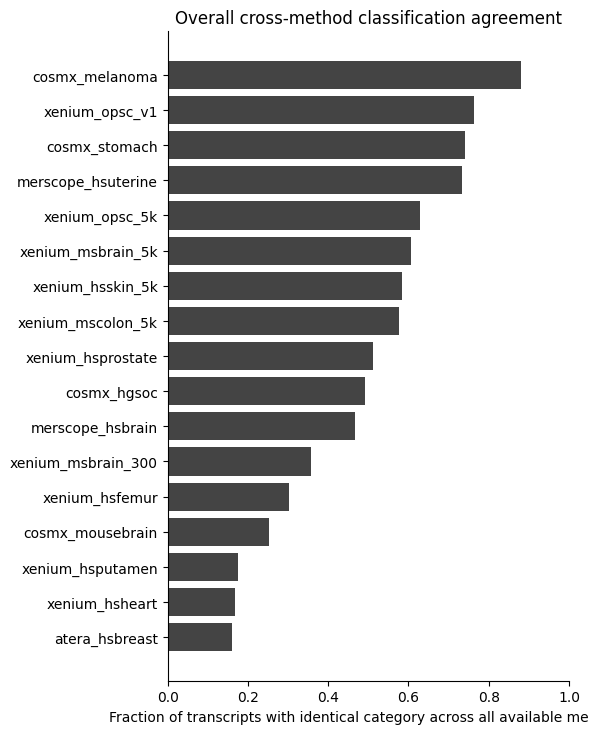

In [9]:
overall = (
    summary_df.loc[summary_df["method_a"] == "ALL"]
    .set_index("sample")["agreement"]
    .sort_values()
)

fig, ax = plt.subplots(figsize=(6, 0.35 * len(overall) + 1.5))
ax.barh(overall.index, overall.values, color="#444444")
ax.set_xlim(0, 1)
ax.set_xlabel("Fraction of transcripts with identical category across all available methods")
ax.set_title("Overall cross-method classification agreement")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(os.path.join(saving_path, f"overall_agreement_by_sample.{ext}"), bbox_inches="tight")
plt.show()

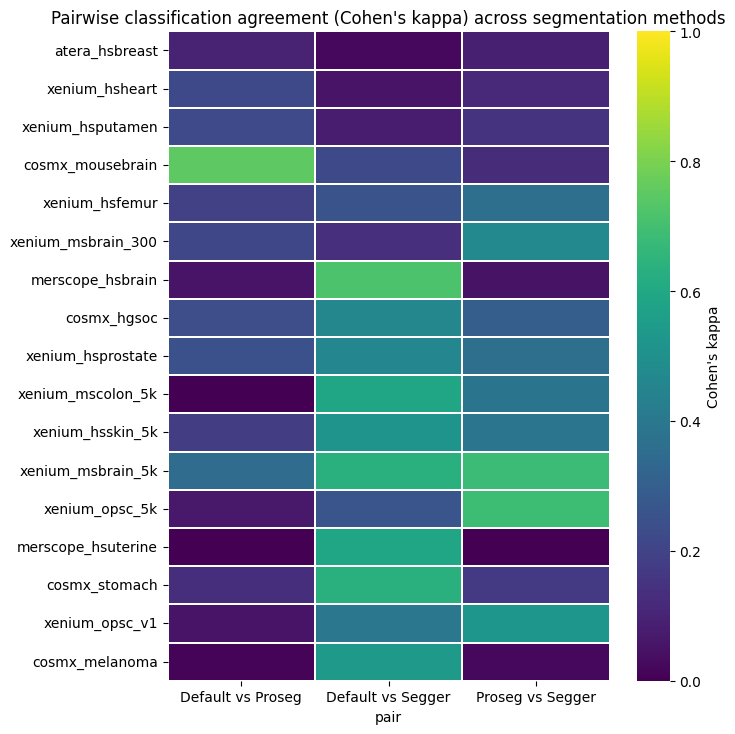

In [10]:
pair_df = summary_df.loc[summary_df["method_a"] != "ALL"].copy()
pair_df["pair"] = pair_df["method_a"].map(method_labels) + " vs " + pair_df["method_b"].map(method_labels)
kappa_pivot = pair_df.pivot(index="sample", columns="pair", values="kappa").reindex(overall.index)

fig, ax = plt.subplots(figsize=(1.8 * kappa_pivot.shape[1] + 2, 0.35 * len(kappa_pivot) + 1.5))
sns.heatmap(
    kappa_pivot, ax=ax, cmap="viridis", vmin=0, vmax=1,
    cbar_kws={"label": "Cohen's kappa"}, linewidths=0.3, linecolor="white",
)
ax.set_title("Pairwise classification agreement (Cohen's kappa) across segmentation methods")
ax.set_ylabel("")
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(os.path.join(saving_path, f"pairwise_kappa_heatmap.{ext}"), bbox_inches="tight")
plt.show()